# Data Preparation

This notebook focuses on end-to-end data cleaning, standarization and preparation of the **Global Electric Vehicle (EV) Adoption Dataset (2010-2025).**
Raw data is rarely ready for immediate analysis. To build reliable visualization and conduct hypothesis testing, we must address inconsistency, missing value and structural mismatch across the source files.


## Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
#drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## Import Libraries/ Modules

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Load data

For consistent access in Colab the recipient should add the folder "OPIM 5606: Data Visualization" to their 'My Drive'.  It can done by right-clicking the folder in 'Shared with me' and selecting 'Add shortcut to Drive' or 'Add to My Drive'.


In [ ]:
# Set the root directory
base_dir = '/content/drive/MyDrive/OPIM 5606: Data Visualization/'

# set the excel file path and pdf path
excel_file_path = base_dir + 'Rawdata/EV Data Explorer 2026.xlsx'
pdf_file_path = base_dir + 'Rawdata/GEVO2026 Policy Explorer.pdf'

In [ ]:
import os
print(os.path.exists('/content/drive/MyDrive/OPIM 5606: Data Visualization/Rawdata/EV Data Explorer 2026.xlsx'))

True


In [ ]:
# View sheet names in the Excel file
EV_xl = pd.ExcelFile(excel_file_path)
print("Sheets:", EV_xl.sheet_names)

Sheets: ['GEVO_EV_2026', 'Notes', 'Definitions', 'Examples >>', 'EV sales countries', 'EV sales macro regions', 'FCEV stock macro regions', 'Other than sales and stock', 'Regions and countries']


In [ ]:
# Extract data based on sheet name
EV_raw_df = pd.read_excel(excel_file_path, sheet_name= "GEVO_EV_2026")
geo_df = pd.read_excel(excel_file_path, sheet_name= "Regions and countries")


# Initial EDA

### 1. Basic Info

In [ ]:
print("="*80)
print("BASIC INFO of EV DATA")
print("-"*80)
EV_raw_df.info()
print("="*80)

BASIC INFO of EV DATA
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49176 entries, 0 to 49175
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   region_country   48098 non-null  object 
 1   category         49176 non-null  object 
 2   parameter        49176 non-null  object 
 3   mode             49176 non-null  object 
 4   powertrain       49176 non-null  object 
 5   year             49176 non-null  int64  
 6   unit             26594 non-null  object 
 7   value            49176 non-null  float64
 8   Aggregate group  49176 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 3.4+ MB


In [ ]:
print("="*80)
print("BASIC DETAILS EV DATA")
print("-"*80)
print(f"Dataset: {excel_file_path}")
print(f"Shape of the dataset: {EV_raw_df.shape}")
print(f"Number of rows: {EV_raw_df.shape[0]}")
print(f"Number of columns: {EV_raw_df.shape[1]}")
print(f"Missing Values: \n{EV_raw_df.isnull().sum()}")
print(f"Duplicate rows: {EV_raw_df.duplicated().sum()}")
print("="*80)

BASIC DETAILS EV DATA
--------------------------------------------------------------------------------
Dataset: /content/drive/MyDrive/OPIM 5606: Data Visualization/Rawdata/EV Data Explorer 2026.xlsx
Shape of the dataset: (49176, 9)
Number of rows: 49176
Number of columns: 9
Missing Values: 
region_country      1078
category               0
parameter              0
mode                   0
powertrain             0
year                   0
unit               22582
value                  0
Aggregate group        0
dtype: int64
Duplicate rows: 15


In [ ]:
print("="*80)
print("BASIC DETAILS REGION COUNTRY (GEO DATA)")
print("-"*80)
print(f"Dataset: {excel_file_path}")
print(f"Shape of the dataset: {geo_df.shape}")
print(f"Number of rows: {geo_df.shape[0]}")
print(f"Number of columns: {geo_df.shape[1]}")
print(f"Missing Values: \n{geo_df.isnull().sum()}")
print(f"Duplicate rows: {geo_df.duplicated().sum()}")
print("="*80)

BASIC DETAILS REGION COUNTRY (GEO DATA)
--------------------------------------------------------------------------------
Dataset: /content/drive/MyDrive/OPIM 5606: Data Visualization/Rawdata/EV Data Explorer 2026.xlsx
Shape of the dataset: (15, 2)
Number of rows: 15
Number of columns: 2
Missing Values: 
region_country    0
Agg_group         0
dtype: int64
Duplicate rows: 0


### 2. Unique value by Column

In [ ]:
print("="*80)
print("UNIQUE VALUE BY COLUMN (EV DATA)")
print("-"*80)
for col in EV_raw_df.columns:
  print(f"{col}: \n{EV_raw_df[col].nunique()} unique| Sample: {EV_raw_df[col].dropna().unique()[:].tolist()}\n")
print("="*80)

UNIQUE VALUE BY COLUMN (EV DATA)
--------------------------------------------------------------------------------
region_country: 
72 unique| Sample: ['Chile', 'Norway', 'Portugal', 'Canada', 'France', 'Germany', 'Italy', 'Netherlands', 'Switzerland', 'Belgium', 'Denmark', 'Finland', 'Spain', 'United Kingdom', 'Greece', 'Iceland', 'Poland', 'Sweden', 'Australia', 'Mexico', 'New Zealand', 'South Africa', 'Thailand', 'Brazil', 'Malaysia', 'Austria', 'Turkiye', 'Colombia', 'Indonesia', 'Israel', 'Jordan', 'Russia', 'Viet Nam', 'Costa Rica', 'Philippines', 'Singapore', 'United Arab Emirates', 'Cambodia', 'Lao PDR', 'Uzbekistan', 'World', 'China', 'Europe', 'India', 'Latin America', 'Japan', 'Korea', 'Southeast Asia', 'USA', 'Advanced Economies', 'Developing Economies excl. China', 'Africa', 'Asia Pacific', 'European Union', 'Middle East and Caspian', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic', 'Estonia', 'Hungary', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Nepal', 'Romania', 

In [ ]:
print("="*80)
print("UNIQUE VALUE BY COLUMN (COUNTRY REGION DATA)")
print("-"*80)
for col in geo_df.columns:
  print(f"{col}: \n{geo_df[col].nunique()} unique| Sample: {geo_df[col].dropna().unique()[:5].tolist()}\n")
print("="*80)

UNIQUE VALUE BY COLUMN (COUNTRY REGION DATA)
--------------------------------------------------------------------------------
region_country: 
15 unique| Sample: ['World', 'Advanced Economies', 'Developing Economies excl. China', 'Africa', 'Europe']

Agg_group: 
5 unique| Sample: ['_World', 'Other_aggregate', 'Projection_region', 'European Union', 'Projection_country']



### 3. COUNTRY vs REGION/AGGREGATE DISTINCTION

In [ ]:
print("="*80)
print("COUNTRY vs REGION/AGGREGATE DISTINCTION")
print("-"*80)
geo_df = pd.read_excel(excel_file_path, sheet_name="Regions and countries")
aggregate_names = set(geo_df['region_country'].tolist())
all_rc = set(EV_raw_df['region_country'].dropna().unique())
country_names = all_rc - aggregate_names

print(f"Total unique region_country values : {len(all_rc)}")
print(f"Aggregate/regional entries         : {len(aggregate_names)}  ← from 'Regions and countries' sheet")
print(f"Individual country entries         : {len(country_names)}")
print(f"\nAggregates: {sorted(aggregate_names)}")
print(f"\nCountries : {sorted(country_names)}")
print("="*80)

COUNTRY vs REGION/AGGREGATE DISTINCTION
--------------------------------------------------------------------------------
Total unique region_country values : 72
Aggregate/regional entries         : 15  ← from 'Regions and countries' sheet
Individual country entries         : 57

Aggregates: ['Advanced Economies', 'Africa', 'Asia Pacific', 'China', 'Developing Economies excl. China', 'Europe', 'European Union', 'India', 'Japan', 'Korea', 'Latin America', 'Middle East and Caspian', 'Southeast Asia', 'USA', 'World']

Countries : ['Argentina', 'Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Cambodia', 'Canada', 'Chile', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Indonesia', 'Ireland', 'Israel', 'Italy', 'Jordan', 'Lao PDR', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Mexico', 'Nepal', 'Netherlands', 'New Zealand', 'Norway', 'Philippines', 'Poland', 'Portugal', 'Roman

### 4. Distribution

DISTRIBUTION PER PARAMETER


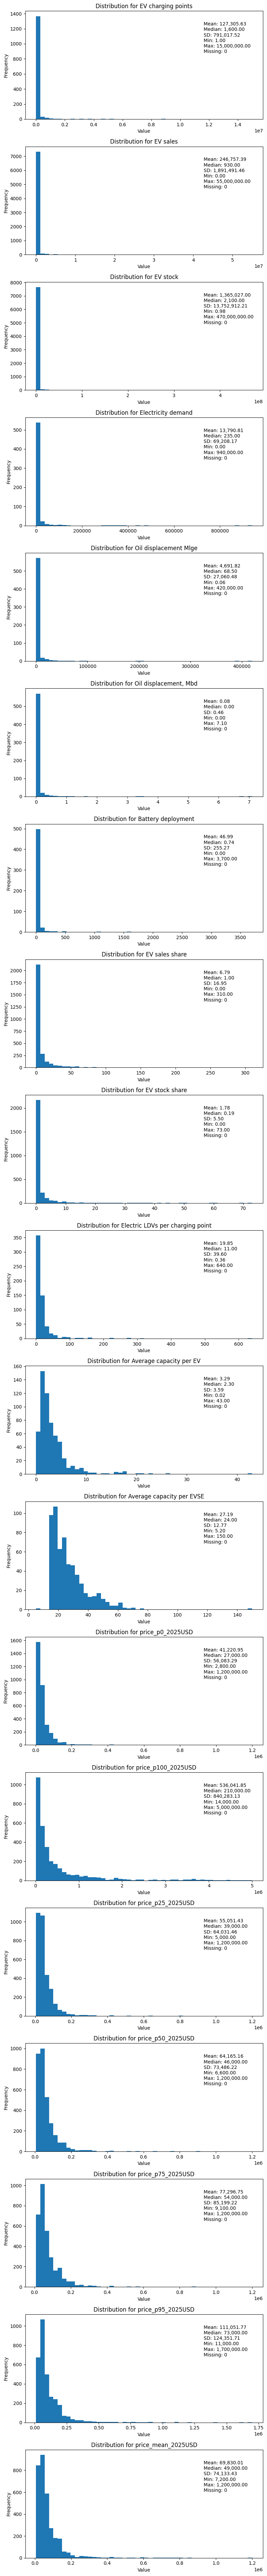

In [ ]:
print("="*80)
print("DISTRIBUTION PER PARAMETER")
parameters = EV_raw_df["parameter"].unique()

fig, axes = plt.subplots(len(parameters), 1, figsize=(8, 4*len(parameters)))

for i, p in enumerate(parameters):
  # get the value for each parameter and drop null values
  data = EV_raw_df[EV_raw_df["parameter"]==p]["value"].dropna()

  axes[i].hist(data, bins=50)
  axes[i].set_title(f"Distribution for {p}")
  axes[i].set_xlabel("Value")
  axes[i].set_ylabel("Frequency")

  # add details as text
  stats_text = (
      f"Mean: {data.mean():,.2f}\n"
      f"Median: {data.median():,.2f}\n"
      f"SD: {data.std():,.2f}\n"
      f"Min: {data.min():,.2f}\n" #removed max and added min since max was duplicate
      f"Max: {data.max():,.2f}\n"
      f"Missing: {EV_raw_df[EV_raw_df['parameter']==p]['value'].isna().sum()}\n"
  )

  axes[i].text(0.75, 0.90, stats_text,
               fontsize=10,
               verticalalignment='top',
               transform=axes[i].transAxes)

plt.tight_layout()
plt.show()


### 5. Year Coverage

In [ ]:
print("="*80)
print("YEAR COVERAGE")
print("-"*80)
print(f"Year Range: {EV_raw_df[EV_raw_df['category']=='Historical']['year'].min()} to {EV_raw_df[EV_raw_df['category']=='Historical']['year'].max()}")
print(f"Rows per year: {EV_raw_df.groupby('year').size().to_string()}")
print("="*80)

YEAR COVERAGE
--------------------------------------------------------------------------------
Year Range: 2010 to 2025
Rows per year: year
2010    1413
2011    1621
2012    2029
2013    2299
2014    2625
2015    3066
2016    3264
2017    3411
2018    3769
2019    3882
2020    1940
2021    3996
2022    3969
2023    3564
2024    3585
2025    3482
2035    1261


### 6. 2020 Data Gap Analysis

In [ ]:
print("="*80)
print("2020 DATA GAP ANALYSIS")
print("-"*80)
print("Note: 2020 has significantly fewer rows (~1,940 vs ~3,500–4,000 for other years).")
print("This appears to be a reporting gap, likely COVID-related, not missing data.\n")

gap_check = (
    EV_raw_df[EV_raw_df['year'].isin([2019, 2020, 2021])]
    .groupby(['year', 'parameter'])
    .size()
    .unstack(fill_value=0)
)
print(gap_check.to_string())
print("="*80)

2020 DATA GAP ANALYSIS
--------------------------------------------------------------------------------
Note: 2020 has significantly fewer rows (~1,940 vs ~3,500–4,000 for other years).
This appears to be a reporting gap, likely COVID-related, not missing data.

parameter  Average capacity per EV  Average capacity per EVSE  Battery deployment  EV charging points  EV sales  EV sales share  EV stock  EV stock share  Electric LDVs per charging point  Electricity demand  Oil displacement Mlge  Oil displacement, Mbd  price_mean_2025USD  price_p0_2025USD  price_p100_2025USD  price_p25_2025USD  price_p50_2025USD  price_p75_2025USD  price_p95_2025USD
year                                                                                                                                                                                                                                                                                                                                                         

### Missing Value Heat Map

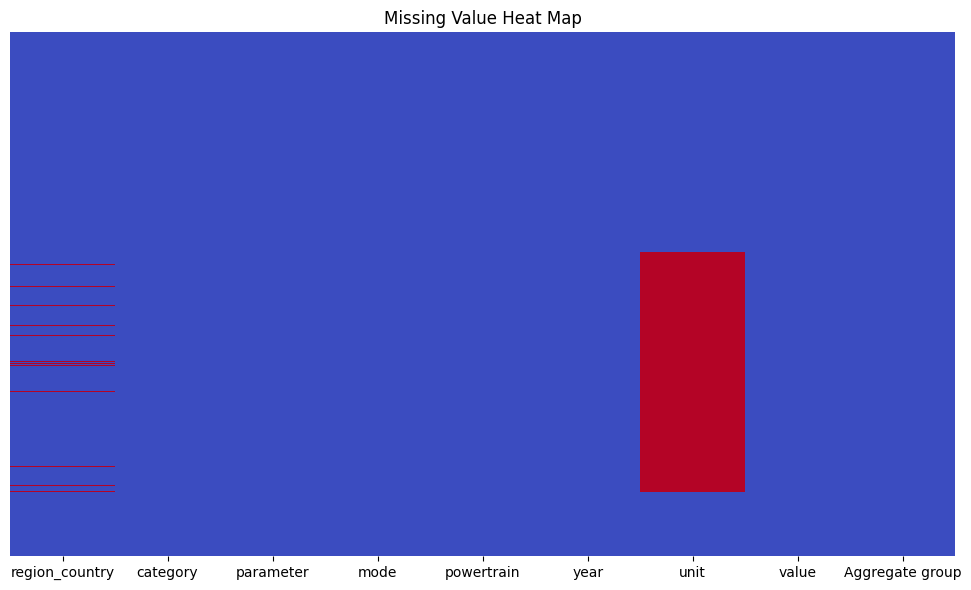


Missing 'unit' by parameter (structural — price rows have no unit in source):
parameter
price_mean_2025USD    3226
price_p0_2025USD      3226
price_p100_2025USD    3226
price_p25_2025USD     3226
price_p50_2025USD     3226
price_p75_2025USD     3226
price_p95_2025USD     3226

Missing 'region_country' by parameter (price parameters are not country-specific):
parameter
price_mean_2025USD    154
price_p0_2025USD      154
price_p100_2025USD    154
price_p25_2025USD     154
price_p50_2025USD     154
price_p75_2025USD     154
price_p95_2025USD     154


In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(EV_raw_df.isnull(), cbar=False, yticklabels = False, cmap="coolwarm")
plt.title("Missing Value Heat Map")
plt.tight_layout()
plt.show()

# There are no nulls in "Value" Column
#print("\nMissing 'value' by parameter:")
#print(EV_raw_df[EV_raw_df["value"].isna()].groupby("parameter").size().to_string())

# CORRECTED
print("\nMissing 'unit' by parameter (structural — price rows have no unit in source):")
print(EV_raw_df[EV_raw_df["unit"].isna()].groupby("parameter").size().to_string())

print("\nMissing 'region_country' by parameter (price parameters are not country-specific):")
print(EV_raw_df[EV_raw_df["region_country"].isna()].groupby("parameter").size().to_string())

In [ ]:
print("="*80)
print(f"MISSING VALUE BY PARAMETER")
print("-"*80)
for param in EV_raw_df["parameter"].unique():
  subset = EV_raw_df[EV_raw_df["parameter"]==param]
  missing = subset[subset["value"].isna()]
  print(f"Parameter: {param}")
  print(f"Total Rows: {len(subset)}")
  print(f"Missing Values: {len(missing)}\n")
print("="*80)


MISSING VALUE BY PARAMETER
--------------------------------------------------------------------------------
Parameter: EV charging points
Total Rows: 1452
Missing Values: 0

Parameter: EV sales
Total Rows: 7581
Missing Values: 0

Parameter: EV stock
Total Rows: 7816
Missing Values: 0

Parameter: Electricity demand
Total Rows: 594
Missing Values: 0

Parameter: Oil displacement Mlge
Total Rows: 622
Missing Values: 0

Parameter: Oil displacement, Mbd
Total Rows: 622
Missing Values: 0

Parameter: Battery deployment
Total Rows: 546
Missing Values: 0

Parameter: EV sales share
Total Rows: 2811
Missing Values: 0

Parameter: EV stock share
Total Rows: 2746
Missing Values: 0

Parameter: Electric LDVs per charging point
Total Rows: 601
Missing Values: 0

Parameter: Average capacity per EV
Total Rows: 601
Missing Values: 0

Parameter: Average capacity per EVSE
Total Rows: 602
Missing Values: 0

Parameter: price_p0_2025USD
Total Rows: 3226
Missing Values: 0

Parameter: price_p100_2025USD
Total Row

### EV Data Start Per Country

In [ ]:
# As mentioned by Farsha
print("="*80)
print(f"EV Start per country")
for param in ["EV sales","EV stock"]:
  subset = EV_raw_df[(EV_raw_df["parameter"]==param)&(EV_raw_df["value"]>0)]
  start_year = subset.groupby("region_country")["year"].min().sort_values().reset_index()
  start_year.columns = ["Country","Start_year"]
  print("-"*80)
  print(f"Parameter: {param}")
  print(start_year.to_string(index = False))
print("="*80)

EV Start per country
--------------------------------------------------------------------------------
Parameter: EV sales
                         Country  Start_year
              Advanced Economies        2010
                    Asia Pacific        2010
                          Brazil        2010
                         Belgium        2010
                           China        2010
                          Canada        2010
Developing Economies excl. China        2010
                           India        2010
                         Germany        2010
                         Iceland        2010
                          Israel        2010
                          France        2010
                          Europe        2010
                  European Union        2010
                         Denmark        2010
                           Italy        2010
                          Poland        2010
                     New Zealand        2010
                     Ne

code for **HANDLING MISSING VALUES** in **unit** AND **region_country** COLUMNS AND as well **REMOVING DUPLICATES**

The missing values in **unit** column are specifically for the below parameters

price_p0_2025USD  
price_p100_2025USD  
price_p25_2025USD  
price_p50_2025USD  
price_p75_2025USD  
price_p95_2025USD

**(3226 missing values per parameter * 7 = 22582)**

"Unit" Column missing values are restored with **2025 USD**

In [ ]:
# Restore unit for all price parameter rows
price_mask = EV_raw_df['parameter'].str.startswith('price_')
EV_raw_df.loc[price_mask, 'unit'] = '2025 USD'

# Verify
print(EV_raw_df[price_mask]['unit'].value_counts())
# → 2025 USD    22582

unit
2025 USD    22582
Name: count, dtype: int64


"region_country" Column missing values are labelled **Unattributed**

In [ ]:
# Flag them as 'Unattributed' — preserve the price data, mark the geography
price_mask = EV_raw_df['parameter'].str.startswith('price_')
null_rc_mask = EV_raw_df['region_country'].isnull()

EV_raw_df.loc[price_mask & null_rc_mask, 'region_country'] = 'Unattributed'

# Verify nothing else is null
print("Remaining nulls in region_country:", EV_raw_df['region_country'].isnull().sum())
# → 0

Remaining nulls in region_country: 0


Confirming handled missing values in **Unit** and **region_country** Columns

In [ ]:
print(f"Missing Values: \n{EV_raw_df.isnull().sum()}")

Missing Values: 
region_country     0
category           0
parameter          0
mode               0
powertrain         0
year               0
unit               0
value              0
Aggregate group    0
dtype: int64


In [ ]:
all_duplicates = EV_raw_df[EV_raw_df.duplicated(keep=False)]
print(all_duplicates)

             region_country    category                         parameter  \
19029  United Arab Emirates  Historical  Electric LDVs per charging point   
19069  United Arab Emirates  Historical  Electric LDVs per charging point   
19109  United Arab Emirates  Historical  Electric LDVs per charging point   
19149  United Arab Emirates  Historical  Electric LDVs per charging point   
19189  United Arab Emirates  Historical  Electric LDVs per charging point   
19211  United Arab Emirates  Historical  Electric LDVs per charging point   
19214  United Arab Emirates  Historical  Electric LDVs per charging point   
19218  United Arab Emirates  Historical  Electric LDVs per charging point   
19222  United Arab Emirates  Historical  Electric LDVs per charging point   
19226  United Arab Emirates  Historical  Electric LDVs per charging point   
19482  United Arab Emirates  Historical           Average capacity per EV   
19522  United Arab Emirates  Historical           Average capacity per EV   

**Checking before dropping the duplicate rows, that whether all columns totally match in the duplicate pairs**

In [ ]:
key_cols = ['region_country', 'category', 'parameter', 'mode', 'powertrain', 'year']

conflicts = (
    EV_raw_df.groupby(key_cols)['value']
    .nunique()
    .reset_index()
    .rename(columns={'value': 'unique_values'})
)
conflicts = conflicts[conflicts['unique_values'] > 1]
print("Key combinations with conflicting values:", len(conflicts))
# → 0   ← confirmed, no conflicts

Key combinations with conflicting values: 0


**Dropping the duplicates**

In [ ]:
# Before
print("Rows before:", len(EV_raw_df))               # 49,176
print("Duplicate rows:", EV_raw_df.duplicated().sum()) # 15

# Drop duplicates — keep first occurrence, drop second
EV_raw_df = EV_raw_df.drop_duplicates(keep='first').reset_index(drop=True)

# After
print("Rows after:", len(EV_raw_df))                # 49,161
print("Duplicate rows:", EV_raw_df.duplicated().sum()) # 0

Rows before: 49176
Duplicate rows: 15
Rows after: 49161
Duplicate rows: 0


### EDA Summary

In [ ]:
print("="*80)
print(f"EDA Summary")
print("-"*80)
print(f"\nDataset: {excel_file_path}")
print(f"\nShape of the dataset: {EV_raw_df.shape}")
print(f"\nNumber of rows: {EV_raw_df.shape[0]}")
print(f"\nNumber of columns: {EV_raw_df.shape[1]}")

#print(f"\nYears covered: {EV_raw_df['year'].min()}-{EV_raw_df['year'].max()}")
# CORRECTED — Year coverage split by whether Historical OR Projection
hist_df = EV_raw_df[EV_raw_df['category'] == 'Historical']
proj_df = EV_raw_df[EV_raw_df['category'] != 'Historical']
print(f"\nHistorical years covered : {hist_df['year'].min()}–{hist_df['year'].max()}")
print(f"Projection years covered : {proj_df['year'].min()}–{proj_df['year'].max()}")
print(f"Projection types         : {proj_df['category'].unique().tolist()}")

print("\nUnique Values:\n")
print(f"  region_country: {EV_raw_df['region_country'].nunique()}")
print(f"  category: {EV_raw_df['category'].nunique()}")
print(f"  parameter: {EV_raw_df['parameter'].nunique()}")
print(f"  mode: {EV_raw_df['mode'].nunique()}")
print(f"  powertrain: {EV_raw_df['powertrain'].nunique()}")
print(f"  unit: {EV_raw_df['unit'].nunique()}")
print(f"  aggregate_group: {EV_raw_df['Aggregate group'].nunique()}")
print(f"\nTotal Missing Values: \n{EV_raw_df.isnull().sum()}")
print(f"\nDuplicate rows:")
print(f"  {EV_raw_df.duplicated().sum()}")
print("="*80)


EDA Summary
--------------------------------------------------------------------------------

Dataset: /content/drive/MyDrive/OPIM 5606: Data Visualization/Rawdata/EV Data Explorer 2026.xlsx

Shape of the dataset: (49161, 9)

Number of rows: 49161

Number of columns: 9

Historical years covered : 2010–2025
Projection years covered : 2035–2035
Projection types         : ['Projection-CPS', 'Projection-STEPS']

Unique Values:

  region_country: 73
  category: 3
  parameter: 19
  mode: 13
  powertrain: 10
  unit: 10
  aggregate_group: 6

Total Missing Values: 
region_country     0
category           0
parameter          0
mode               0
powertrain         0
year               0
unit               0
value              0
Aggregate group    0
dtype: int64

Duplicate rows:
  0


# Data Preparation

### 1.Define Mapping

In [ ]:
# If you create the aggregates first and then rename the the below countries
# (USA, Viet Nam, Lao PDR, Turkiye, Korea), you may missclassify South Korea and USA as countries, but actualy them being aggregates

#AGGREGATES =  set(geo_df["region_country"].unique())


COUNTRY_NAME_MAP = {
    "USA": "United States",
    "Viet Nam": "Vietnam",
    "Lao PDR": "Laos",
    "Turkiye": "Turkey",
    "Korea": "South Korea"
}

AGGREGATES = set(geo_df["region_country"].replace(COUNTRY_NAME_MAP).unique())

print("AGGREGATES (post-rename):")
print(sorted(AGGREGATES))

# NOTE: India, Japan, China, South Korea, United States are IEA aggregates
# 57 Countries are mapped with the region (57 unique countries were verified somewhere in the above analysis)

IEA_COUNTRY_REGION_MAP = {
    #Latin America
    "Chile": "Latin America",
    "Brazil": "Latin America",
    "Colombia": "Latin America",
    "Argentina": "Latin America",
    "Uruguay": "Latin America",
    "Mexico": "Latin America",
    "Costa Rica": "Latin America",

    #Europe
    "Norway": "Europe",
    "Portugal": "Europe",
    "France": "Europe",
    "Germany": "Europe",
    "Italy": "Europe",
    "Netherlands": "Europe",
    "Switzerland": "Europe",
    "Belgium": "Europe",
    "Denmark": "Europe",
    "Finland": "Europe",
    "Spain": "Europe",
    "United Kingdom": "Europe",
    "Greece": "Europe",
    "Iceland": "Europe",
    "Poland": "Europe",
    "Sweden": "Europe",
    "Austria": "Europe",
    "Romania": "Europe",
    "Czech Republic": "Europe",
    "Estonia": "Europe",
    "Hungary": "Europe",
    "Ireland": "Europe",
    "Latvia": "Europe",
    "Lithuania": "Europe",
    "Luxembourg": "Europe",
    "Slovakia": "Europe",
    "Slovenia": "Europe",
    "Croatia": "Europe",
    "Cyprus": "Europe",
    "Bulgaria": "Europe",


    # Asia Pacific
    "Australia": "Asia Pacific",
    "New Zealand": "Asia Pacific",
    # India, China, Japan are aggregate entries
    #"China": "Asia Pacific",
    #"India": "Asia Pacific",
    #"Japan": "Asia Pacific",
    #"South Korea": "Asia Pacific",
    "Nepal": "Asia Pacific",
    "Uzbekistan": "Asia Pacific",
    "Canada": "Advanced Economies",

    #Southeast Asia
    "Cambodia": "Southeast Asia",
    "Philippines": "Southeast Asia",
    "Singapore": "Southeast Asia",
    "Thailand": "Southeast Asia",
    "Indonesia": "Southeast Asia",
    "Malaysia": "Southeast Asia",
    "Vietnam": "Southeast Asia",
    "Laos": "Southeast Asia",



    # Africa,
    "South Africa": "Africa",
    "Seychelles": "Africa",

    # Mddle East and caspian
    "Jordan": "Middle East and Caspian",
    "United Arab Emirates": "Middle East and Caspian",
    "Turkey": "Middle East and Caspian",
    "Russia": "Middle East and Caspian",
    "Israel": "Middle East and Caspian",

}

AGGREGATES (post-rename):
['Advanced Economies', 'Africa', 'Asia Pacific', 'China', 'Developing Economies excl. China', 'Europe', 'European Union', 'India', 'Japan', 'Latin America', 'Middle East and Caspian', 'South Korea', 'Southeast Asia', 'United States', 'World']


### Clean Data

In [ ]:
df = EV_raw_df.copy()

In [ ]:
df["region_country"] = df["region_country"].str.strip()
df["value"] =  pd.to_numeric(df["value"], errors='coerce')
df["year"] = pd.to_numeric(df["year"], errors='coerce')
df["region_country"] = df["region_country"].replace(COUNTRY_NAME_MAP)

# set geo_type: is the row a country or region aggregate
df["Geo_type"] = df["region_country"].apply(lambda x: "aggregate" if x in AGGREGATES else "country")

# This mapping was modified to take care of the Unattributed regions as well
#df["Region"] = df["region_country"].apply(lambda x: IEA_COUNTRY_REGION_MAP.get(x, pd.NA))

# Aggregates get their own name as Region; countries look up the map;
# Unattributed gets its own label
def assign_region(row):
    if row["Geo_type"] == "aggregate":
        return row["region_country"]          # e.g. 'Europe', 'World', 'South Korea'
    if row["region_country"] == "Unattributed":
        return "Unattributed"
    return IEA_COUNTRY_REGION_MAP.get(row["region_country"], pd.NA)

df["Region"] = df.apply(assign_region, axis=1)


# This mapping was modified to take care of the Unattributed regions as well
#df["Country"] = df.apply(lambda row: pd.NA if row["Geo_type"] == "aggregate" else row["region_country"], axis=1)

# Aggregate rows have no single country; Unattributed rows have unknown country
def assign_country(row):
    if row["Geo_type"] == "aggregate":
        return pd.NA
    if row["region_country"] == "Unattributed":
        return pd.NA
    return row["region_country"]

df["Country"] = df.apply(assign_country, axis=1)

#analysis group
# df['Analysis_group'] = df['region_country'].apply(get_analysis_group)

#rename columns
df = df.rename(columns ={
    "region_country": "Region_Country",
    "category": "Category",
    "parameter": "Parameter",
    "powertrain": "Powertrain",
    "mode": "Mode",
    "value": "Value",
    "year": "Year",
    "unit":"Unit",
    "Aggregate group": "Aggregate_group"
})


#reorder columns
df = df[["Aggregate_group", "Geo_type", "Region_Country", "Region", "Country", "Category", "Parameter", "Powertrain", "Mode", "Value", "Unit", "Year"]]

# Modified as below
#unmapped = df[(df["Geo_type"]=="country") & (df["Region"]=="Other")]["Region_Country"].unique()
#print("Unmapped countries:", unmapped)

print("="*65)
print("STANDARDISATION VALIDATION")
print("-"*65)

# Check no unmapped countries remain
unmapped = df[
    (df["Geo_type"] == "country") &
    (df["Region_Country"] != "Unattributed") &
    (df["Region"].isna())
]["Region_Country"].unique()
print(f"Unmapped countries (should be 0): {sorted(unmapped)}")

# Check Korea/USA aggregate fix worked
for name in ["South Korea", "United States"]:
    geo = df[df["Region_Country"] == name]["Geo_type"].unique().tolist()
    print(f"{name} Geo_type: {geo}  ← should be ['aggregate']")

# Check Unattributed handling
unatt = df[df["Region_Country"] == "Unattributed"][["Geo_type","Region","Country"]].drop_duplicates()
print(f"Unattributed row profile:\n{unatt}")

print("-"*65)
print(f"Final shape      : {df.shape}")
print(f"Null values      :\n{df.isnull().sum()}")
print("="*65)

df.head(10)

STANDARDISATION VALIDATION
-----------------------------------------------------------------
Unmapped countries (should be 0): []
South Korea Geo_type: ['aggregate']  ← should be ['aggregate']
United States Geo_type: ['aggregate']  ← should be ['aggregate']
Unattributed row profile:
      Geo_type        Region Country
20616  country  Unattributed    <NA>
-----------------------------------------------------------------
Final shape      : (49161, 12)
Null values      :
Aggregate_group        0
Geo_type               0
Region_Country         0
Region                 0
Country            18718
Category               0
Parameter              0
Powertrain             0
Mode                   0
Value                  0
Unit                   0
Year                   0
dtype: int64


,Aggregate_group,Geo_type,Region_Country,Region,Country,Category,Parameter,Powertrain,Mode,Value,Unit,Year
0,Other,country,Chile,Latin America,Chile,Historical,EV charging points,Publicly available fast,EVSE,1.0,charging points,2011
1,Other,country,Norway,Europe,Norway,Historical,EV charging points,Publicly available fast,EVSE,18.0,charging points,2011
2,Other,country,Portugal,Europe,Portugal,Historical,EV charging points,Publicly available fast,EVSE,6.0,charging points,2011
3,Other,country,Canada,Advanced Economies,Canada,Historical,EV charging points,Publicly available fast,EVSE,2.0,charging points,2012
4,Other,country,Chile,Latin America,Chile,Historical,EV charging points,Publicly available fast,EVSE,4.0,charging points,2012
5,Other,country,France,Europe,France,Historical,EV charging points,Publicly available fast,EVSE,9.0,charging points,2012
6,Other,country,Germany,Europe,Germany,Historical,EV charging points,Publicly available fast,EVSE,18.0,charging points,2012
7,Other,country,Italy,Europe,Italy,Historical,EV charging points,Publicly available fast,EVSE,1.0,charging points,2012
8,Other,country,Netherlands,Europe,Netherlands,Historical,EV charging points,Publicly available fast,EVSE,21.0,charging points,2012
9,Other,country,Norway,Europe,Norway,Historical,EV charging points,Publicly available fast,EVSE,58.0,charging points,2012


In [ ]:
# ── Country null explanation ───────────────────────────────
print("="*65)
print("COUNTRY NULL BREAKDOWN — ALL INTENTIONAL")
print("-"*65)

agg_nulls  = (df["Geo_type"] == "aggregate").sum()
unatt_nulls = (df["Region_Country"] == "Unattributed").sum()

print(f"Total null Country values : {df['Country'].isnull().sum()}")
print(f"  Aggregate rows (World, Europe, China etc.) : {agg_nulls}")
print(f"  Unattributed rows (unknown price geography): {unatt_nulls}")
print(f"  Unexplained nulls                          : {df['Country'].isnull().sum() - agg_nulls - unatt_nulls}")
print()
print("These nulls are correct by design:")
print("  - Aggregate rows represent regional/global rollups, not a single country.")
print("  - Unattributed rows have real price data but unknown market origin.")
print("  - In Tableau, filter Geo_type == 'country' to work with country-level data.")
print("="*65)

COUNTRY NULL BREAKDOWN — ALL INTENTIONAL
-----------------------------------------------------------------
Total null Country values : 18718
  Aggregate rows (World, Europe, China etc.) : 17640
  Unattributed rows (unknown price geography): 1078
  Unexplained nulls                          : 0

These nulls are correct by design:
  - Aggregate rows represent regional/global rollups, not a single country.
  - Unattributed rows have real price data but unknown market origin.
  - In Tableau, filter Geo_type == 'country' to work with country-level data.


In [ ]:
# ── Save cleaned master dataset ───────────────────────────────────────────────
output_path = base_dir + 'EV_data_cleaned.xlsx'

with pd.ExcelWriter(output_path, engine='openpyxl', mode='w') as writer:
    df.to_excel(writer, sheet_name='Master', index=False)

print("Saved successfully!")
print(f"Path   : {output_path}")
print(f"Sheet  : Master")
print(f"Shape  : {df.shape}")       # → (49161, 12)
print(f"Columns: {df.columns.tolist()}")

Saved successfully!
Path   : /content/drive/MyDrive/OPIM 5606: Data Visualization/EV_data_cleaned.xlsx
Sheet  : Master
Shape  : (49161, 12)
Columns: ['Aggregate_group', 'Geo_type', 'Region_Country', 'Region', 'Country', 'Category', 'Parameter', 'Powertrain', 'Mode', 'Value', 'Unit', 'Year']


### Handle Year Gap

**Missing Values in Charging Points Indicators**
1) For all the rows of Charging points there are zero null values (NA) in all the columns
2) But the problem is with some countries started reporting their charging points at different years, for example - Norway reported the data about charging points from 2011, but where as Singapore started reporting the charging points data from 2024. **In total, the problem is with countries that have gaps across years**

In [ ]:
import pandas as pd
import numpy as np

base_dir = '/content/drive/MyDrive/OPIM 5606: Data Visualization/'

In [ ]:
# ── Step 1: Load Anupama's cleaned file ──────────────────────

df_clean = pd.read_excel(base_dir + 'EV_data_cleaned.xlsx', sheet_name='Master')
print("Loaded shape:", df_clean.shape)
print("Columns:", df_clean.columns.tolist())

Loaded shape: (49161, 12)
Columns: ['Aggregate_group', 'Geo_type', 'Region_Country', 'Region', 'Country', 'Category', 'Parameter', 'Powertrain', 'Mode', 'Value', 'Unit', 'Year']


In [ ]:
# ── Step 2: Filter to charging points, Historical, country rows only ──

charging = df_clean[
    (df_clean['Parameter']  == 'EV charging points') &
    (df_clean['Category']   == 'Historical') &
    (df_clean['Geo_type']   == 'country')
].copy()

print("Charging country rows:", len(charging))
print("Countries:", charging['Country'].nunique())
print("Charger types:", charging['Powertrain'].unique())
print("Year range:", charging['Year'].min(), "–", charging['Year'].max())

Charging country rows: 910
Countries: 37
Charger types: ['Publicly available fast' 'Publicly available slow'
 'Publicly available ultra-fast']
Year range: 2010 – 2025


In [ ]:
# ── Step 3: Confirm no real country is unmapped ───────────────────────────────
# Use 'charging' (defined in Step 2)

cp_countries  = charging[charging['Geo_type'] == 'country']    # ← was overwritten in original
cp_aggregates = charging[charging['Geo_type'] == 'aggregate']  # ← was never defined in original

print(f"Country rows  : {len(cp_countries)}")
print(f"Aggregate rows: {len(cp_aggregates)}")   # → 0, charging is already filtered to country

# Check if any country row is missing a Region
unmapped = cp_countries[cp_countries['Region'].isna()]['Region_Country'].unique()
print(f"\nUnmapped countries (no Region assigned): {unmapped}")  # → []

Country rows  : 910
Aggregate rows: 0

Unmapped countries (no Region assigned): []


### Handle Missing Values

In [ ]:
import numpy as np

# ── Step 4: Handle INTERNAL year gaps only ────────────────────────────────────
#
# Two distinct situations exist in this data:
#
#   A) Late starters (32 of 37 countries): a country begins reporting after 2010
#      and has no gaps between its first and last year.
#      e.g. Singapore reports only 2024–2025. It had no public chargers before —
#      filling 2010–2023 with NaN would misrepresent this as "unknown data."
#      → Do NOT add rows before a country's first reporting year.
#
#   B) Internal gaps (5 combos across 3 countries): a country has a missing year
#      BETWEEN two years where it does have data.
#      e.g. Greece fast: has 2014, then jumps to 2020 — years 2015–2019 are gaps.
#      → These should be filled with NaN (data was not reported that year).
#
# The fix: only expand years between each country's OWN first and last year,
# not from the global minimum year 2010.

expanded_rows = []

for (country, powertrain), group in charging.groupby(['Country', 'Powertrain']):
    year_set     = set(group['Year'])
    country_start = int(group['Year'].min())
    country_end   = int(group['Year'].max())
    template      = group.iloc[0]  # use first row as template for metadata fields

    for yr in range(country_start, country_end + 1):
        if yr not in year_set:
            expanded_rows.append({
                'Aggregate_group': template['Aggregate_group'],
                'Geo_type':        'country',
                'Region_Country':  template['Region_Country'],
                'Region':          template['Region'],
                'Country':         country,
                'Category':        'Historical',
                'Parameter':       'EV charging points',
                'Powertrain':      powertrain,
                'Mode':            template['Mode'],
                'Value':           np.nan,
                'Unit':            'charging points',   # ← was missing in original
                'Year':            yr,
            })

gaps_df = pd.DataFrame(expanded_rows) if expanded_rows else pd.DataFrame(columns=charging.columns)
cp_full = pd.concat([charging, gaps_df], ignore_index=True) \
            .sort_values(['Country', 'Powertrain', 'Year']) \
            .reset_index(drop=True)

print(f"Original charging country rows : {len(charging)}")    # → 910
print(f"Gap rows added (internal only) : {len(gaps_df)}")     # → 14
print(f"Total after expansion          : {len(cp_full)}")     # → 924
print(f"Rows with missing Value        : {cp_full['Value'].isna().sum()}")  # → 14
print(f"Null Unit values               : {cp_full['Unit'].isna().sum()}")   # → 0

Original charging country rows : 910
Gap rows added (internal only) : 14
Total after expansion          : 924
Rows with missing Value        : 14
Null Unit values               : 0


In [ ]:
# ── Step 5: Validate the 5 gapped combos are now complete ─────────────────────
print("="*65)
print("GAP FILL VERIFICATION")
print("-"*65)

gapped_combos = [
    ('Greece', 'Publicly available fast'),
    ('Greece', 'Publicly available ultra-fast'),
    ('Poland', 'Publicly available slow'),
    ('Poland', 'Publicly available ultra-fast'),
    ('Turkey', 'Publicly available ultra-fast'),
]

for country, pt in gapped_combos:
    sub = cp_full[(cp_full['Country'] == country) & (cp_full['Powertrain'] == pt)]
    null_yrs = sorted(sub[sub['Value'].isna()]['Year'].tolist())
    print(f"{country} / {pt}")
    print(f"  Rows: {len(sub)} | Null years (gaps): {null_yrs}")

print("-"*65)
print(f"All columns present : {cp_full.columns.tolist()}")
print(f"Null Unit values    : {cp_full['Unit'].isna().sum()}")   # → 0
print(f"Null Value rows     : {cp_full['Value'].isna().sum()}")  # → 14
print("="*65)

GAP FILL VERIFICATION
-----------------------------------------------------------------
Greece / Publicly available fast
  Rows: 12 | Null years (gaps): [2015, 2016, 2017, 2018, 2019]
Greece / Publicly available ultra-fast
  Rows: 11 | Null years (gaps): [2016, 2017, 2020]
Poland / Publicly available slow
  Rows: 12 | Null years (gaps): [2015]
Poland / Publicly available ultra-fast
  Rows: 12 | Null years (gaps): [2016, 2017, 2018, 2019]
Turkey / Publicly available ultra-fast
  Rows: 6 | Null years (gaps): [2021]
-----------------------------------------------------------------
All columns present : ['Aggregate_group', 'Geo_type', 'Region_Country', 'Region', 'Country', 'Category', 'Parameter', 'Powertrain', 'Mode', 'Value', 'Unit', 'Year']
Null Unit values    : 0
Null Value rows     : 14


In [ ]:
# ── Step 6 — appends to existing file ─────────────────────────────────
import os

output_path = base_dir + 'EV_data_cleaned.xlsx'

# Safety check — tells you clearly if Anupama's save hasn't run yet
if not os.path.exists(output_path):
    raise FileNotFoundError(
        f"Master file not found at {output_path}.\n"
        "Run Anupama's save cell first before running Farasha's notebook."
    )

with pd.ExcelWriter(output_path, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    cp_full.to_excel(writer, sheet_name='Charging_Points', index=False)

print("Charging_Points sheet saved!")
print(f"Shape : {cp_full.shape}")     # → (924, 12)

# Confirm both sheets are present
saved = pd.ExcelFile(output_path).sheet_names
print(f"Sheets in file: {saved}")     # → ['Master', 'Charging_Points']

Charging_Points sheet saved!
Shape : (924, 12)
Sheets in file: ['Master', 'Charging_Points']


In [ ]:
#════════════════════════════════════════════════════════════════════
#  Validate `Mode` / `Powertrain` (controlled-vocabulary check)
#  Continuation cell — robust to kernel restarts & column renaming
# ════════════════════════════════════════════════════════════════════
import pandas as pd
import os

# ── Step 1: Load from the cleaned Master sheet ───────────────────────
cleaned_path = base_dir + 'EV_data_cleaned.xlsx'

if not os.path.exists(cleaned_path):
    raise FileNotFoundError(
        f"Cleaned file not found at: {cleaned_path}\n"
        "Run Anupama's notebook first to generate EV_data_cleaned.xlsx."
    )

data = pd.read_excel(cleaned_path, sheet_name='Master')

print("Loaded from  : EV_data_cleaned.xlsx → Master sheet")
print("Shape        :", data.shape)           # → (49161, 12)
print("Columns      :", data.columns.tolist())
print("Nulls        :\n", data.isnull().sum())

# ── Step 2: Expected values per IEA GEVO 2026 schema ────────────────
VALID_MODE = {
    "Cars", "All cars", "2 and 3 wheelers", "Vans", "Buses", "Trucks",
    "City car", "Small SUV/Pick-up", "Medium car", "Large car",
    "Large SUV/Pick-up", "EV", "EVSE",
}

VALID_POWERTRAIN = {
    # Task scope: BEV, PHEV, FCEV
    "BEV",    # Battery Electric Vehicle
    "PHEV",   # Plug-in Hybrid Electric Vehicle
    "FCEV",   # Fuel Cell Electric Vehicle
    # Additional IEA schema values present in this dataset
    "EV",     # Generic EV aggregate (stock/sales rollup rows)
    "ICEV",   # Internal Combustion Engine — price comparison rows (9,268 rows)
    "EREV",   # Extended Range EV — price rows (686 rows)
    "ALL",    # All-powertrain aggregate — price 'All cars' rows (1,568 rows)
    # Charging point subtypes — only paired with Mode = EVSE
    "Publicly available slow",
    "Publicly available fast",
    "Publicly available ultra-fast",
}

# ── Step 3: Validation function ──────────────────────────────────────
def validate_categorical(df, col, allowed):
    s = df[col]
    print(f"\n=== {col} ===")

    # 1. Nulls
    print(f"  Nulls: {s.isna().sum()}")

    # 2. Whitespace
    nonnull = s.dropna().astype(str)
    ws = (nonnull != nonnull.str.strip()).sum()
    print(f"  Values with leading/trailing whitespace: {ws}")

    # 3. Casing/spacing collisions
    case_dupes = (
        nonnull.str.lower().str.strip().nunique() != nonnull.str.strip().nunique()
    )
    print(f"  Casing/spacing collisions present: {case_dupes}")

    # 4. Unexpected values
    found      = set(nonnull.str.strip().unique())
    unexpected = found - allowed
    missing    = allowed - found
    print(f"  Unexpected values (NOT in allowed set): {sorted(unexpected) or 'none'}")
    print(f"  Allowed-but-absent values: {sorted(missing) or 'none'}")

    # 5. Value counts
    print("  Value counts:")
    print("    " + s.value_counts(dropna=False).to_string().replace("\n", "\n    "))
    return unexpected

bad_mode = validate_categorical(data, "Mode", VALID_MODE)
bad_pt   = validate_categorical(data, "Powertrain", VALID_POWERTRAIN)

# ── Step 4: Cross-consistency checks ────────────────────────────────

# Check 1: EVSE rows should only carry charging powertrains
charging_pts = {
    "Publicly available slow",
    "Publicly available fast",
    "Publicly available ultra-fast"
}
evse_pts = set(data.loc[data["Mode"] == "EVSE", "Powertrain"].unique())
evse_ok  = evse_pts.issubset(charging_pts)

print("\n=== Cross-consistency: EVSE ===")
print(f"  EVSE powertrain values   : {sorted(evse_pts)}")
print(f"  Only charging powertrains: {evse_ok}")

# Check 2: Parameter × Mode consistency
# Each parameter should only appear with its expected Mode group
VEHICLE_MODES = {"Cars", "Vans", "Trucks", "Buses", "2 and 3 wheelers"}
CHARGING_MODE = {"EVSE"}

PARAM_MODE_RULES = {
    "EV sales":           VEHICLE_MODES,
    "EV stock":           VEHICLE_MODES,
    "EV sales share":     VEHICLE_MODES,
    "EV stock share":     VEHICLE_MODES,
    "EV charging points": CHARGING_MODE,
}

print("\n=== Cross-consistency: Parameter × Mode ===")
param_mode_ok = True
for param, expected in PARAM_MODE_RULES.items():
    actual     = set(data[data["Parameter"] == param]["Mode"].unique())
    unexpected = actual - expected
    if unexpected:
        print(f"  FAIL  {param}: unexpected modes → {unexpected}")
        param_mode_ok = False
    else:
        print(f"  OK    {param}: {sorted(actual)}")

# Check 3: Vehicle modes should not appear with charging powertrains
print("\n=== Cross-consistency: Vehicle modes × charging powertrains ===")
vehicle_with_charging = data[
    data["Mode"].isin(VEHICLE_MODES) &
    data["Powertrain"].isin(charging_pts)
]
print(f"  Vehicle mode rows with charging powertrains: {len(vehicle_with_charging)}")
print(f"  {'OK — none found' if len(vehicle_with_charging) == 0 else 'REVIEW NEEDED'}")

# ── Step 5: Final verdict ────────────────────────────────────────────
print("\n" + "=" * 60)
all_ok = not bad_mode and not bad_pt and evse_ok and param_mode_ok
if all_ok:
    print("PASS — Mode & Powertrain validated, no anomalies.")
    print(f"  Mode       : {data['Mode'].nunique()} unique values, all valid")
    print(f"  Powertrain : {data['Powertrain'].nunique()} unique values, all valid")
    print(f"  Source     : EV_data_cleaned.xlsx → Master ({data.shape[0]:,} rows)")
else:
    print("REVIEW NEEDED — see flagged values above.")
print("=" * 60)

Loaded from  : EV_data_cleaned.xlsx → Master sheet
Shape        : (49161, 12)
Columns      : ['Aggregate_group', 'Geo_type', 'Region_Country', 'Region', 'Country', 'Category', 'Parameter', 'Powertrain', 'Mode', 'Value', 'Unit', 'Year']
Nulls        :
 Aggregate_group        0
Geo_type               0
Region_Country         0
Region                 0
Country            18718
Category               0
Parameter              0
Powertrain             0
Mode                   0
Value                  0
Unit                   0
Year                   0
dtype: int64

=== Mode ===
  Nulls: 0
  Values with leading/trailing whitespace: 0
  Casing/spacing collisions present: False
  Unexpected values (NOT in allowed set): none
  Allowed-but-absent values: none
  Value counts:
    Mode
    Cars                 7872
    All cars             5964
    2 and 3 wheelers     4615
    Vans                 4321
    Buses                3955
    Medium car           3780
    Large car            3465
    Sm

### Data Reshaping

In [ ]:
# ─────────────────────────────────────────────────────────
# 0.  SETUP — run this cell first in Colab
# ─────────────────────────────────────────────────────────
# !pip install openpyxl -q    # usually pre-installed in Colab

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
from functools import reduce

# ─────────────────────────────────────────────────────────
# 1.  PATHS
# ─────────────────────────────────────────────────────────
base_dir = '/content/drive/MyDrive/OPIM 5606: Data Visualization/'

import os

input_path  = base_dir + 'EV_data_cleaned.xlsx'

sheet_name  = 'Master'

output_path = base_dir + 'EV_master_analytical.xlsx'


if not os.path.exists(input_path):

    raise FileNotFoundError(

        f"Cleaned file not found at: {input_path}\n"

        "Run Anupama's notebook first to generate EV_data_cleaned.xlsx."

    )

print("✅  Reading from EV_data_cleaned.xlsx → Master sheet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅  Reading from EV_data_cleaned.xlsx → Master sheet


In [ ]:
# ─────────────────────────────────────────────────────────
# 2.  LOAD
# ─────────────────────────────────────────────────────────
print(f"Loading: {input_path}  |  sheet: {sheet_name}")
df_raw = pd.read_excel(input_path, sheet_name=sheet_name)
print(f"Raw shape: {df_raw.shape}\n")

Loading: /content/drive/MyDrive/OPIM 5606: Data Visualization/EV_data_cleaned.xlsx  |  sheet: Master
Raw shape: (49161, 12)



In [ ]:
# ─────────────────────────────────────────────────────────
# 3.  ASSIGN WORKING DATAFRAME
# ─────────────────────────────────────────────────────────
df = df_raw.copy()
print(f"Working shape: {df.shape}")
print(f"Columns      : {df.columns.tolist()}\n")

# ── Split Historical from Projections ─────────────────────────────

# Projection rows cover year 2035 only for 9 aggregate locations.

# All three pivots use df_hist so Tableau gets a clean historical-only

# dataset. df_proj is saved separately as Master_Projection sheet.

df_hist = df[df['Category'] == 'Historical'].copy()

df_proj = df[df['Category'] != 'Historical'].copy()


print(f"Historical rows : {len(df_hist):,}")

print(f"Projection rows : {len(df_proj):,}  (Projection-CPS + Projection-STEPS, year 2035 only)")

print(f"Projection locations: {sorted(df_proj['Region_Country'].unique())}")

Working shape: (49161, 12)
Columns      : ['Aggregate_group', 'Geo_type', 'Region_Country', 'Region', 'Country', 'Category', 'Parameter', 'Powertrain', 'Mode', 'Value', 'Unit', 'Year']

Historical rows : 47,900
Projection rows : 1,261  (Projection-CPS + Projection-STEPS, year 2035 only)
Projection locations: ['China', 'Europe', 'India', 'Japan', 'Latin America', 'South Korea', 'Southeast Asia', 'United States', 'World']


In [ ]:
# ─────────────────────────────────────────────────────────
# 4.  KEY CONSTANT: base index shared by all output sheets
# ─────────────────────────────────────────────────────────
#BASE_INDEX = ['Aggregate_group', 'Geo_type', 'Region_Country','Region', 'Country', 'Category', 'Year']

PIVOT_INDEX = ['Aggregate_group','Geo_type','Region_Country',
               'Region','Category','Year']

In [ ]:
# ─────────────────────────────────────────────────────────
# 5.  PIVOT A — MASTER ANALYTICAL DATASET
#
#     One row per (Region_Country, Category, Year)
#     Columns:
#       EV_Sales_Cars_Total / _BEV / _PHEV
#       EV_Stock_Cars_Total / _BEV / _PHEV
#       EV_Sales_Share_Cars   (%)
#       EV_Stock_Share_Cars   (%)
#       Charging_Fast / _Slow / _UltraFast / _Total
#       EVs_per_Charger       (derived ratio)
# ─────────────────────────────────────────────────────────
print("=" * 65)
print("PIVOT A: Master Analytical (one row per location-year)")
print("=" * 65)

# ── EV Sales — Cars ──────────────────────────────────────
sales_cars = df_hist[
    (df_hist['Parameter'] == 'EV sales') &
    (df_hist['Mode']      == 'Cars')     &
    (df_hist['Powertrain'].isin(['EV', 'BEV', 'PHEV', 'FCEV']))  # ← FCEV added
]
p_sales = sales_cars.pivot_table(
    index=PIVOT_INDEX, columns='Powertrain', values='Value', aggfunc='sum'
).reset_index()
p_sales.columns.name = None
p_sales = p_sales.rename(columns={
    'EV': 'EV_Sales_Cars_Total', 'BEV': 'EV_Sales_Cars_BEV', 'PHEV': 'EV_Sales_Cars_PHEV', 'FCEV': 'EV_Sales_Cars_FCEV',             # ← new column
})
print(f"  EV Sales pivot  : {p_sales.shape}")

# ── EV Stock — Cars ──────────────────────────────────────
stock_cars = df_hist[
    (df_hist['Parameter'] == 'EV stock') &
    (df_hist['Mode']      == 'Cars')     &
    (df_hist['Powertrain'].isin(['EV', 'BEV', 'PHEV', 'FCEV']))  # ← FCEV added
]
p_stock = stock_cars.pivot_table(
    index=PIVOT_INDEX, columns='Powertrain', values='Value', aggfunc='sum'
).reset_index()
p_stock.columns.name = None
p_stock = p_stock.rename(columns={
    'EV': 'EV_Stock_Cars_Total', 'BEV': 'EV_Stock_Cars_BEV', 'PHEV': 'EV_Stock_Cars_PHEV', 'FCEV': 'EV_Stock_Cars_FCEV',             # ← new column
})
print(f"  EV Stock pivot  : {p_stock.shape}")

# ── EV Sales Share — Cars ────────────────────────────────
p_sales_share = df_hist[
    (df_hist['Parameter']  == 'EV sales share') &
    (df_hist['Mode']       == 'Cars')            &
    (df_hist['Powertrain'] == 'EV')
][PIVOT_INDEX + ['Value']].rename(columns={'Value': 'EV_Sales_Share_Cars'})
print(f"  Sales share     : {p_sales_share.shape}")

# ── EV Stock Share — Cars ────────────────────────────────
p_stock_share = df_hist[
    (df_hist['Parameter']  == 'EV stock share') &
    (df_hist['Mode']       == 'Cars')            &
    (df_hist['Powertrain'] == 'EV')
][PIVOT_INDEX + ['Value']].rename(columns={'Value': 'EV_Stock_Share_Cars'})
print(f"  Stock share     : {p_stock_share.shape}")

# ── Charging Points ──────────────────────────────────────
charging = df_hist[
    (df_hist['Parameter'] == 'EV charging points') &
    (df_hist['Mode']      == 'EVSE')
]
p_charging = charging.pivot_table(
    index=PIVOT_INDEX, columns='Powertrain', values='Value', aggfunc='sum'
).reset_index()
p_charging.columns.name = None
p_charging = p_charging.rename(columns={
    'Publicly available fast'      : 'Charging_Fast',
    'Publicly available slow'      : 'Charging_Slow',
    'Publicly available ultra-fast': 'Charging_UltraFast',
})
cp_cols = [c for c in ['Charging_Fast', 'Charging_Slow', 'Charging_UltraFast']
           if c in p_charging.columns]
p_charging['Charging_Total'] = p_charging[cp_cols].sum(axis=1, min_count=1)
print(f"  Charging pivot  : {p_charging.shape}")

# ── Merge all pivots on BASE_INDEX (outer join keeps all locations) ──
master = reduce(
    lambda left, right: pd.merge(left, right, on=PIVOT_INDEX, how='outer'),
    [p_sales, p_stock, p_sales_share, p_stock_share, p_charging]
)

# Re-derive Country after merge
master['Country'] = master.apply(
    lambda r: pd.NA if r['Geo_type'] == 'aggregate' else r['Region_Country'],
    axis=1
)

# ── Derived metric ────────────────────────────────────────
# EV_Stock_Cars_Total uses Powertrain='EV' = IEA total (BEV+PHEV+FCEV combined).

# This matches IEA's own 'Electric LDVs per charging point' metric (Cars only).

# For the full IEA LDV ratio use Parameter='Electric LDVs per charging point' directly.
valid_charger = (master['Charging_Total'] > 0) & master['EV_Stock_Cars_Total'].notna()
master['EVs_per_Charger'] = np.where(
    valid_charger,
    master['EV_Stock_Cars_Total'] / master['Charging_Total'],
    np.nan
)

master = master.sort_values(['Region_Country', 'Category', 'Year']).reset_index(drop=True)
print(f"\n  ✅ Master Analytical: {master.shape[0]:,} rows × {master.shape[1]} columns")
print(f"  Duplicate keys: {master.duplicated(subset=['Region_Country','Category','Year']).sum()}")

print("\n  Sample — Norway Historical 2022–2024:")
samp = master[
    (master['Region_Country'] == 'Norway') &
    (master['Category']       == 'Historical') &
    (master['Year'].between(2022, 2024))
]
print(samp[['Region_Country','Year','EV_Sales_Cars_Total','EV_Stock_Cars_Total',
            'EV_Sales_Share_Cars','Charging_Total','EVs_per_Charger']].to_string(index=False))



PIVOT A: Master Analytical (one row per location-year)
  EV Sales pivot  : (915, 10)
  EV Stock pivot  : (767, 10)
  Sales share     : (912, 7)
  Stock share     : (766, 7)
  Charging pivot  : (564, 10)

  ✅ Master Analytical: 928 rows × 22 columns
  Duplicate keys: 0

  Sample — Norway Historical 2022–2024:
Region_Country  Year  EV_Sales_Cars_Total  EV_Stock_Cars_Total  EV_Sales_Share_Cars  Charging_Total  EVs_per_Charger
        Norway  2022             150000.0             790000.0                 89.0         25100.0        31.474104
        Norway  2023             110000.0             900000.0                 90.0         28400.0        31.690141
        Norway  2024             120000.0            1000000.0                 92.0         31900.0        31.347962


In [ ]:
# ─────────────────────────────────────────────────────────
# 6.  PIVOT B — CARS BY TECHNOLOGY (BEV / PHEV / FCEV)
#
#     One row per (Region_Country, Category, Year, Powertrain)
#     Use this for technology market share charts.
# ─────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("PIVOT B: Cars by Technology (BEV / PHEV / FCEV)")
print("=" * 65)

TECH_INDEX = PIVOT_INDEX + ['Powertrain']

b_sales = df_hist[
    (df_hist['Parameter']  == 'EV sales') &
    (df_hist['Mode']       == 'Cars')      &
    (df_hist['Powertrain'].isin(['BEV', 'PHEV', 'FCEV']))
][TECH_INDEX + ['Value']].rename(columns={'Value': 'EV_Sales_Cars'})

b_stock = df_hist[
    (df_hist['Parameter']  == 'EV stock') &
    (df_hist['Mode']       == 'Cars')      &
    (df_hist['Powertrain'].isin(['BEV', 'PHEV', 'FCEV']))
][TECH_INDEX + ['Value']].rename(columns={'Value': 'EV_Stock_Cars'})

master_cars_tech = b_sales.merge(b_stock, on=TECH_INDEX, how='outer')
master_cars_tech = master_cars_tech.sort_values(
    ['Region_Country', 'Category', 'Year', 'Powertrain']).reset_index(drop=True)

print(f"  ✅ Cars by Tech: {master_cars_tech.shape[0]:,} rows × {master_cars_tech.shape[1]} columns")

print("\n  Sample — China Historical 2023:")
samp_b = master_cars_tech[
    (master_cars_tech['Region_Country'] == 'China') &
    (master_cars_tech['Category']       == 'Historical') &
    (master_cars_tech['Year']           == 2023)
]
print(samp_b[['Region_Country','Year','Powertrain','EV_Sales_Cars','EV_Stock_Cars']].to_string(index=False))



PIVOT B: Cars by Technology (BEV / PHEV / FCEV)
  ✅ Cars by Tech: 2,119 rows × 9 columns

  Sample — China Historical 2023:
Region_Country  Year Powertrain  EV_Sales_Cars  EV_Stock_Cars
         China  2023        BEV      5500000.0     16000000.0
         China  2023       FCEV          520.0          760.0
         China  2023       PHEV      2700000.0      5500000.0


In [ ]:
# ─────────────────────────────────────────────────────────
# 7.  PIVOT C — ALL VEHICLE MODES SUMMARY
#
#     One row per (Region_Country, Category, Year, Mode)
#     Covers Cars / Buses / Trucks / Vans / 2-and-3-wheelers
# ─────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("PIVOT C: All Vehicle Modes (Cars/Buses/Trucks/Vans/2-3W)")
print("=" * 65)

MODE_INDEX = PIVOT_INDEX + ['Mode']

c_sales = df_hist[
    (df_hist['Parameter']  == 'EV sales') &
    (df_hist['Powertrain'] == 'EV')               # EV = total across all powertrains
][MODE_INDEX + ['Value']].rename(columns={'Value': 'EV_Sales_Total'})

c_stock = df_hist[
    (df_hist['Parameter']  == 'EV stock') &
    (df_hist['Powertrain'] == 'EV')
][MODE_INDEX + ['Value']].rename(columns={'Value': 'EV_Stock_Total'})

master_all_modes = c_sales.merge(c_stock, on=MODE_INDEX, how='outer')
master_all_modes = master_all_modes.sort_values(
    ['Region_Country', 'Category', 'Year', 'Mode']).reset_index(drop=True)

print(f"  ✅ All Modes: {master_all_modes.shape[0]:,} rows × {master_all_modes.shape[1]} columns")

print("\n  Sample — China Historical 2024 all modes:")
samp_c = master_all_modes[
    (master_all_modes['Region_Country'] == 'China') &
    (master_all_modes['Category']       == 'Historical') &
    (master_all_modes['Year']           == 2024)
]
print(samp_c[['Region_Country','Year','Mode','EV_Sales_Total','EV_Stock_Total']].to_string(index=False))


PIVOT C: All Vehicle Modes (Cars/Buses/Trucks/Vans/2-3W)
  ✅ All Modes: 2,887 rows × 9 columns

  Sample — China Historical 2024 all modes:
Region_Country  Year             Mode  EV_Sales_Total  EV_Stock_Total
         China  2024 2 and 3 wheelers       6700000.0      66000000.0
         China  2024            Buses         39000.0        670000.0
         China  2024             Cars      11000000.0      32000000.0
         China  2024           Trucks        180000.0        570000.0
         China  2024             Vans        100000.0        240000.0


In [ ]:
# ─────────────────────────────────────────────────────────
# 8.  VALIDATION
# ─────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("VALIDATION REPORT")
print("=" * 65)

def validate(name, df_v, key_cols):
    print(f"\n── {name} ──")
    print(f"  Shape         : {df_v.shape}")
    dups = df_v.duplicated(subset=key_cols).sum()
    print(f"  Duplicate keys: {dups}  {'✅' if dups == 0 else '⚠️  FIX NEEDED'}")
    metric_cols = [c for c in df_v.columns if c not in key_cols]
    for col in metric_cols:
        null_pct = df_v[col].isna().mean() * 100
        flag = '⚠️ ' if null_pct > 80 else ''
        print(f"  {flag}{col:<35} null: {null_pct:5.1f}%")

validate("Master_Analytical",
         master,            ['Region_Country', 'Category', 'Year'])
validate("Master_Cars_Tech",
         master_cars_tech,  ['Region_Country', 'Category', 'Year', 'Powertrain'])
validate("Master_All_Modes",
         master_all_modes,  ['Region_Country', 'Category', 'Year', 'Mode'])


VALIDATION REPORT

── Master_Analytical ──
  Shape         : (928, 22)
  Duplicate keys: 0  ✅
  Aggregate_group                     null:   0.0%
  Geo_type                            null:   0.0%
  Region                              null:   0.0%
  EV_Sales_Cars_BEV                   null:   2.6%
  EV_Sales_Cars_Total                 null:   1.5%
  EV_Sales_Cars_FCEV                  null:  66.8%
  EV_Sales_Cars_PHEV                  null:  14.3%
  EV_Stock_Cars_BEV                   null:  17.8%
  EV_Stock_Cars_Total                 null:  17.5%
  EV_Stock_Cars_FCEV                  null:  60.2%
  EV_Stock_Cars_PHEV                  null:  26.7%
  EV_Sales_Share_Cars                 null:   1.7%
  EV_Stock_Share_Cars                 null:  17.5%
  Charging_Fast                       null:  43.1%
  Charging_Slow                       null:  40.0%
  Charging_UltraFast                  null:  66.3%
  Charging_Total                      null:  39.2%
  Country                             

In [ ]:
# ── Verify World rows are already in master from Pivot A ─────────────────────
# Note: the PIVOT_INDEX fix (removing Country from pivot index) already ensures
# World is included in all pivots with real Sales and Stock values.
# No concat needed — World rows are already present and populated.

world_check = master[master['Region_Country'] == 'World'][
    ['Year', 'EV_Sales_Cars_Total', 'EV_Stock_Cars_Total']
].sort_values('Year')

print('=== World rows in Master Analytical (from Pivot A) ===')
print(world_check.to_string(index=False))
print(f'Total World rows : {len(world_check)}')        # → 16
print(f'Duplicates       : {master.duplicated(subset=["Region_Country","Category","Year"]).sum()}')  # → 0
print(f'Final shape      : {master.shape}')             # → (928, 22)

=== World rows in Master Analytical (from Pivot A) ===
 Year  EV_Sales_Cars_Total  EV_Stock_Cars_Total
 2010               7400.0              39000.0
 2011              49000.0              95000.0
 2012             120000.0             220000.0
 2013             210000.0             420000.0
 2014             330000.0             730000.0
 2015             530000.0            1300000.0
 2016             780000.0            2000000.0
 2017            1200000.0            3200000.0
 2018            2000000.0            5100000.0
 2019            2100000.0            7100000.0
 2020            3000000.0           10000000.0
 2021            6600000.0           16000000.0
 2022           10000000.0           26000000.0
 2023           14000000.0           40000000.0
 2024           17000000.0           56000000.0
 2025           21000000.0           75000000.0
Total World rows : 16
Duplicates       : 0
Final shape      : (928, 22)


In [ ]:
# ─────────────────────────────────────────────────────────
# 9.  SAVE
# ─────────────────────────────────────────────────────────
print(f"\n{'=' * 65}")
print(f"Saving → {output_path}")
print("=" * 65)

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    master.to_excel(writer,           sheet_name='Master_Analytical', index=False)
    master_cars_tech.to_excel(writer, sheet_name='Master_Cars_Tech',  index=False)
    master_all_modes.to_excel(writer, sheet_name='Master_All_Modes',  index=False)
    df_proj.to_excel(writer,          sheet_name='Master_Projection', index=False)

print(f"\n✅  Saved successfully!")
print(f"   Master_Analytical : {master.shape[0]:,} rows × {master.shape[1]} cols")
print(f"   Master_Cars_Tech  : {master_cars_tech.shape[0]:,} rows × {master_cars_tech.shape[1]} cols")
print(f"   Master_All_Modes  : {master_all_modes.shape[0]:,} rows × {master_all_modes.shape[1]} cols")
print(f"   Master_Projection : {df_proj.shape[0]:,} rows × {df_proj.shape[1]} cols")
print()
print("─" * 65)
print("NEXT STEPS")
print("─" * 65)
print("1. Share EV_master_analytical.xlsx with the team for Phase 3 dashboards.")
print("2. In Tableau → connect to Master_Analytical as the primary data source.")
print("   Filter Geo_type == 'country' for country-level maps and comparisons.")
print("3. In Tableau → connect to Master_Analytical as the primary data source.")
print("   Use Master_Cars_Tech for BEV/PHEV/FCEV technology breakdown charts.")
print("   Use Master_All_Modes for bus/truck/van cross-mode comparison charts.")
print("4. Use Master_Projection for year-2035 scenario comparison (CPS vs STEPS).")
print("─" * 65)


Saving → /content/drive/MyDrive/OPIM 5606: Data Visualization/EV_master_analytical.xlsx

✅  Saved successfully!
   Master_Analytical : 928 rows × 22 cols
   Master_Cars_Tech  : 2,119 rows × 9 cols
   Master_All_Modes  : 2,887 rows × 9 cols
   Master_Projection : 1,261 rows × 12 cols

─────────────────────────────────────────────────────────────────
NEXT STEPS
─────────────────────────────────────────────────────────────────
1. Share EV_master_analytical.xlsx with the team for Phase 3 dashboards.
2. In Tableau → connect to Master_Analytical as the primary data source.
   Filter Geo_type == 'country' for country-level maps and comparisons.
3. In Tableau → connect to Master_Analytical as the primary data source.
   Use Master_Cars_Tech for BEV/PHEV/FCEV technology breakdown charts.
   Use Master_All_Modes for bus/truck/van cross-mode comparison charts.
4. Use Master_Projection for year-2035 scenario comparison (CPS vs STEPS).
──────────────────────────────────────────────────────────────

In [ ]:
import pandas as pd

# ── Define paths ──────────────────────────────────────────────────────────────
base_dir    = '/content/drive/MyDrive/OPIM 5606: Data Visualization/'
input_path  = base_dir + 'EV_master_analytical.xlsx'
output_path = input_path

# ── Load ──────────────────────────────────────────────────────────────────────
df = pd.read_excel(input_path, sheet_name='Master_Analytical')
print(f"Loaded Master_Analytical: {df.shape}")

# ── Shape guard ───────────────────────────────────────────────────────────────
if df.shape[0] != 928:                          # ← changed from 944 to 928
    raise ValueError(
        f"Master_Analytical has {df.shape[0]} rows — expected 928.\n"
        "The file has likely been overwritten by a previous bad run.\n"
        "Ask Vishal to re-run the reshape notebook to regenerate the clean file."
    )
print(f"Shape check passed — {df.shape[0]} rows loaded.")

Loaded Master_Analytical: (928, 22)
Shape check passed — 928 rows loaded.


**Global Market Share and Regional Market Share**

NOTE: Entity Classification

The 'country' entity type here includes both true individual countries
(e.g. Germany, Norway) and major market aggregates (China, India, Japan,
South Korea, United States) which are IEA top-level entries representing
entire markets not broken down further in this dataset.

This does NOT cause double counting in regional market share because
China, India, Japan, South Korea and United States each have Region values
equal to their own name (e.g. Region = 'China') rather than a shared
regional bucket (e.g. 'Asia Pacific'). So they never get summed together
with individual countries in the regional groupby.

For interpretation: global share figures mix individual countries with
major market aggregates. China's 45.9M sales represents the entire Chinese
market as a single IEA entry. This is a data source limitation not a
calculation error. In Tableau, always filter by Geo_type or Entity_Type
to avoid mixing these two types on the same chart without clear labelling.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ── Paths ─────────────────────────────────────────────────────────────────────
base_dir    = '/content/drive/MyDrive/OPIM 5606: Data Visualization/'
input_path  = base_dir + 'EV_master_analytical.xlsx'
output_path = input_path

# ── Load ──────────────────────────────────────────────────────────────────────
df = pd.read_excel(input_path, sheet_name='Master_Analytical')
print(f"Loaded Master_Analytical: {df.shape}")

# ── Shape guard ───────────────────────────────────────────────────────────────
# File must have either 928 rows (without World rows) or 944 (with World rows)
if df.shape[0] not in [928, 944]:
    raise ValueError(
        f"Master_Analytical has {df.shape[0]} rows — expected 928 or 944.\n"
        "The file has been overwritten by a previous bad run.\n"
        "Ask Vishal to re-run the reshape notebook to regenerate the clean file."
    )
print(f"Shape check passed — {df.shape[0]} rows loaded.")

# ── Run-once guard ────────────────────────────────────────────────────────────
# If Farasha's columns already exist, stop immediately.
# This prevents row explosion from re-running on an already-processed file.
FARASHA_COLUMNS = [
    'My_Global_Sales_Share_Pct', 'My_Global_Stock_Share_Pct',
    'My_Regional_Sales_Share_Pct', 'My_Regional_Stock_Share_Pct'
]
if all(col in df.columns for col in FARASHA_COLUMNS):
    print("="*60)
    print("Farasha's columns already present in the file.")
    print(f"Current shape: {df.shape}")
    print("Skipping all calculations to prevent row explosion.")
    print("To re-run from scratch, ask Vishal to regenerate")
    print("EV_master_analytical.xlsx first, then re-run this notebook.")
    print("="*60)
else:
    print("Farasha's columns not found — proceeding with calculations.")


# NOTE: Entity Classification
# The 'country' entity type here includes both true individual countries
# (e.g. Germany, Norway) and major market aggregates (China, India, Japan,
# South Korea, United States) which are IEA top-level entries representing
# entire markets not broken down further in this dataset.
#
# This does NOT cause double counting in regional market share because
# China, India, Japan, South Korea and United States each have Region values
# equal to their own name (e.g. Region = 'China') rather than a shared
# regional bucket (e.g. 'Asia Pacific'). So they never get summed together
# with individual countries in the regional groupby.

BIG_COUNTRY_AGGREGATES = [
    'China', 'India', 'Japan', 'South Korea', 'United States'
]
REGION_ROLLUPS = [
    'Advanced Economies', 'Africa', 'Asia Pacific',
    'Developing Economies excl. China', 'Europe', 'European Union',
    'Latin America', 'Middle East and Caspian', 'Southeast Asia'
]

def classify(row):
    if row['Region_Country'] == 'World':        return 'world'
    if row['Region_Country'] in REGION_ROLLUPS: return 'region_rollup'
    if row['Geo_type'] == 'country' or row['Region_Country'] in BIG_COUNTRY_AGGREGATES:
        return 'country'
    return 'other'

df['Entity_Type'] = df.apply(classify, axis=1)
print("Entity type counts:")
print(df['Entity_Type'].value_counts())

hist         = df[df['Category'] == 'Historical'].copy()
country_only = hist[hist['Entity_Type'] == 'country'].copy()

Loaded Master_Analytical: (928, 22)
Shape check passed — 928 rows loaded.
Farasha's columns not found — proceeding with calculations.
Entity type counts:
Entity_Type
country          772
region_rollup    140
world             16
Name: count, dtype: int64


In [ ]:

world_totals = hist[hist['Entity_Type'] == 'world'][[
    'Year', 'EV_Sales_Cars_Total', 'EV_Stock_Cars_Total'
]].rename(columns={
    'EV_Sales_Cars_Total': 'World_Sales_Total',
    'EV_Stock_Cars_Total': 'World_Stock_Total'
})

regional_totals = country_only.groupby(['Region', 'Year']).agg(
    Region_Sales_Total=('EV_Sales_Cars_Total', 'sum'),
    Region_Stock_Total=('EV_Stock_Cars_Total', 'sum')
).reset_index()

print(f"World totals rows    : {len(world_totals)}")
print(f"Regional totals rows : {len(regional_totals)}")

World totals rows    : 16
Regional totals rows : 189


In [ ]:
# 4. Calculate GLOBAL market share

global_calc = country_only.merge(world_totals, on='Year', how='left')
global_calc['My_Global_Sales_Share_Pct'] = (
    global_calc['EV_Sales_Cars_Total'] / global_calc['World_Sales_Total'] * 100
)
global_calc['My_Global_Stock_Share_Pct'] = (
    global_calc['EV_Stock_Cars_Total'] / global_calc['World_Stock_Total'] * 100
)
print(f"Global calc shape: {global_calc.shape}")




Global calc shape: (772, 27)


In [ ]:
# 5. Calculate REGIONAL market share

regional_calc = country_only.merge(regional_totals, on=['Region', 'Year'], how='left')
regional_calc['My_Regional_Sales_Share_Pct'] = (
    regional_calc['EV_Sales_Cars_Total'] / regional_calc['Region_Sales_Total'] * 100
)
regional_calc['My_Regional_Stock_Share_Pct'] = (
    regional_calc['EV_Stock_Cars_Total'] / regional_calc['Region_Stock_Total'] * 100
)
print(f"Regional calc shape: {regional_calc.shape}")

Regional calc shape: (772, 27)


In [ ]:
# 6. Build the 4 new columns, keyed by Region_Country + Year
# Build 4 new columns keyed by Region_Country + Year
new_cols = global_calc[[
    'Region_Country', 'Year',
    'My_Global_Sales_Share_Pct', 'My_Global_Stock_Share_Pct'
]].merge(
    regional_calc[[
        'Region_Country', 'Year',
        'My_Regional_Sales_Share_Pct', 'My_Regional_Stock_Share_Pct'
    ]],
    on=['Region_Country', 'Year'], how='left'
)

# Drop duplicates before merge — prevents row explosion
new_cols = new_cols.drop_duplicates(subset=['Region_Country', 'Year'])
print(f"New cols shape    : {new_cols.shape}")
print(f"Duplicates check  : {new_cols.duplicated(subset=['Region_Country','Year']).sum()}")

# Merge onto full df
df = df.merge(new_cols, on=['Region_Country', 'Year'], how='left')

# Verify shape did not explode
print(f"\nShape after merge : {df.shape}")
print(f"Duplicate rows    : {df.duplicated(subset=['Region_Country','Category','Year']).sum()}")

# Sanity check
print("\nSanity check — global sales share should sum to ~100% per year:")
print(global_calc.groupby('Year')['My_Global_Sales_Share_Pct'].sum().round(1).to_string())

# Verification note
print("\n" + "=" * 70)
print("VERIFICATION NOTE")
print("-" * 70)
print("My_Global/Regional_*_Share_Pct = this country's share of the")
print("  global/regional EV TOTAL (market share by volume)")
print("EV_Sales_Share_Cars / EV_Stock_Share_Cars (existing columns) =")
print("  EV share of THIS COUNTRY'S total car sales/stock (adoption rate)")
print("These are different metrics — do not expect them to match.")
print("=" * 70)

# Save — mode='a' keeps all other sheets, if_sheet_exists='replace' overwrites only Master_Analytical
with pd.ExcelWriter(output_path, engine='openpyxl', mode='a',
                    if_sheet_exists='replace') as writer:
    df.to_excel(writer, sheet_name='Master_Analytical', index=False)

print(f"\nSaved successfully!")
print(f"Shape : {df.shape}")       # → (928, 27) or (944, 27)
print(f"Columns added: {FARASHA_COLUMNS}")
print(f"Path  : {output_path}")

New cols shape    : (772, 6)
Duplicates check  : 0

Shape after merge : (928, 27)
Duplicate rows    : 0

Sanity check — global sales share should sum to ~100% per year:
Year
2010     93.1
2011     99.8
2012     97.5
2013     98.0
2014     99.9
2015     97.7
2016     99.8
2017     99.6
2018    102.1
2019    103.1
2020     98.1
2021     99.2
2022    102.1
2023     97.1
2024     99.9
2025     97.6

VERIFICATION NOTE
----------------------------------------------------------------------
My_Global/Regional_*_Share_Pct = this country's share of the
  global/regional EV TOTAL (market share by volume)
EV_Sales_Share_Cars / EV_Stock_Share_Cars (existing columns) =
  EV share of THIS COUNTRY'S total car sales/stock (adoption rate)
These are different metrics — do not expect them to match.

Saved successfully!
Shape : (928, 27)
Columns added: ['My_Global_Sales_Share_Pct', 'My_Global_Stock_Share_Pct', 'My_Regional_Sales_Share_Pct', 'My_Regional_Stock_Share_Pct']
Path  : /content/drive/MyDrive/OPIM

In [ ]:
# Re-load from the saved file to ensure we are working on clean data
df_eda = pd.read_excel(input_path, sheet_name='Master_Analytical')

# Re-classify if needed
if 'Entity_Type' not in df_eda.columns:
    df_eda['Entity_Type'] = df_eda.apply(classify, axis=1)

country_df = df_eda[df_eda['Entity_Type'] == 'country'].copy()
country_df = country_df.sort_values(['Region_Country', 'Year'])

country_df['Charging_YoY_Growth_Pct'] = (
    country_df.groupby('Region_Country')['Charging_Total']
    .pct_change(fill_method=None) * 100
)
country_df['EV_Stock_YoY_Growth_Pct'] = (
    country_df.groupby('Region_Country')['EV_Stock_Cars_Total']
    .pct_change(fill_method=None) * 100
)

print(f"Country rows: {len(country_df)}")
print(f"Missing Charging_Total     : {country_df['Charging_Total'].isnull().sum()}")
print(f"Missing EV_Stock_Cars_Total: {country_df['EV_Stock_Cars_Total'].isnull().sum()}")

valid = country_df.dropna(
    subset=['Charging_YoY_Growth_Pct', 'EV_Stock_YoY_Growth_Pct']
)

pearson_r  = valid['Charging_YoY_Growth_Pct'].corr(valid['EV_Stock_YoY_Growth_Pct'], method='pearson')
spearman_r = valid['Charging_YoY_Growth_Pct'].corr(valid['EV_Stock_YoY_Growth_Pct'], method='spearman')

print("\n" + "=" * 70)
print("CORRELATION: Charging Growth % vs EV Stock Growth %")
print("-" * 70)
print(f"Country-year pairs used     : {len(valid)}")
print(f"Pearson  (linear)           : {pearson_r:.3f}")
print(f"Spearman (rank)             : {spearman_r:.3f}")
print("-" * 70)
print("Interpretation:")
print("  0.7–1.0 → strong  |  0.3–0.7 → moderate  |  <0.3 → weak")
print("=" * 70)

pearson_r_val, pearson_p   = stats.pearsonr(
    valid['Charging_YoY_Growth_Pct'], valid['EV_Stock_YoY_Growth_Pct'])
spearman_r_val, spearman_p = stats.spearmanr(
    valid['Charging_YoY_Growth_Pct'], valid['EV_Stock_YoY_Growth_Pct'])

print(f"\nPearson:  r={pearson_r_val:.3f}, p={pearson_p:.4f}  "
      f"{'significant' if pearson_p < 0.05 else 'NOT significant'} at 0.05")
print(f"Spearman: r={spearman_r_val:.3f}, p={spearman_p:.4f}  "
      f"{'significant' if spearman_p < 0.05 else 'NOT significant'} at 0.05")

# Outlier analysis
valid_clean = valid[
    (valid['Charging_YoY_Growth_Pct'] <= 500) &
    (valid['EV_Stock_YoY_Growth_Pct']  <= 500)
].copy()
pearson_clean, p_clean = stats.pearsonr(
    valid_clean['Charging_YoY_Growth_Pct'],
    valid_clean['EV_Stock_YoY_Growth_Pct']
)
print(f"\nPearson after capping outliers >500%: r={pearson_clean:.3f}, p={p_clean:.4f}")
print(f"Outlier rows removed: {len(valid) - len(valid_clean)}")

# Per-country correlation
per_country_corr = (
    valid.groupby('Region_Country')
    .apply(lambda g: g['Charging_YoY_Growth_Pct'].corr(g['EV_Stock_YoY_Growth_Pct'])
           if len(g) >= 3 else None, include_groups=False)
    .dropna()
    .sort_values(ascending=False)
)
print(f"\nPer-country correlation (3+ valid years): {len(per_country_corr)} countries")
print("\nTop 5 strongest positive relationships:")
print(per_country_corr.head(5).to_string())
print("\nBottom 5 (weakest or negative):")
print(per_country_corr.tail(5).to_string())


Country rows: 772
Missing Charging_Total     : 335
Missing EV_Stock_Cars_Total: 161

CORRELATION: Charging Growth % vs EV Stock Growth %
----------------------------------------------------------------------
Country-year pairs used     : 394
Pearson  (linear)           : 0.051
Spearman (rank)             : 0.304
----------------------------------------------------------------------
Interpretation:
  0.7–1.0 → strong  |  0.3–0.7 → moderate  |  <0.3 → weak

Pearson:  r=0.051, p=0.3115  NOT significant at 0.05
Spearman: r=0.304, p=0.0000  significant at 0.05

Pearson after capping outliers >500%: r=0.395, p=0.0000
Outlier rows removed: 12

Per-country correlation (3+ valid years): 40 countries

Top 5 strongest positive relationships:
Region_Country
Vietnam          0.965107
United States    0.961842
Israel           0.954746
Costa Rica       0.941227
Switzerland      0.815362

Bottom 5 (weakest or negative):
Region_Country
Russia                 -0.286323
United Arab Emirates   -0.444375


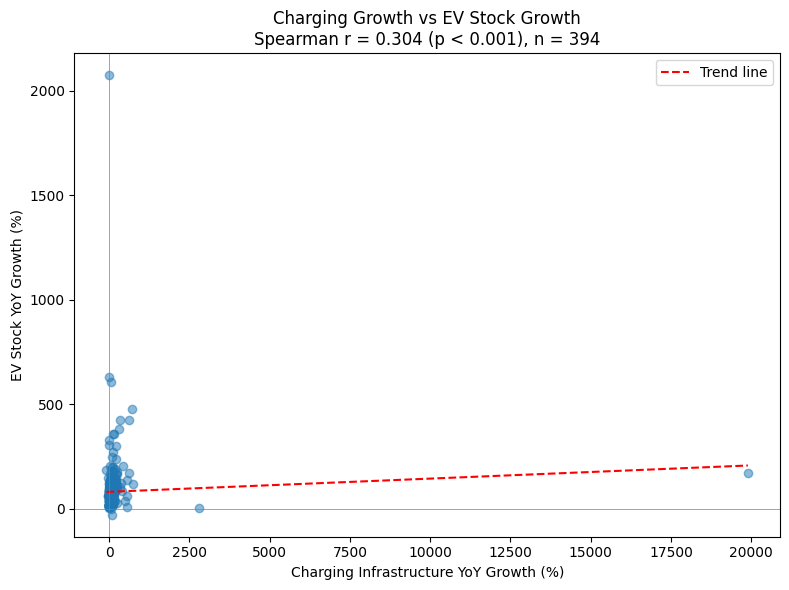

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    valid['Charging_YoY_Growth_Pct'],
    valid['EV_Stock_YoY_Growth_Pct'],
    alpha=0.5
)

# Trend line
z      = np.polyfit(valid['Charging_YoY_Growth_Pct'],
                    valid['EV_Stock_YoY_Growth_Pct'], 1)
p_line = np.poly1d(z)
x_line = np.linspace(
    valid['Charging_YoY_Growth_Pct'].min(),
    valid['Charging_YoY_Growth_Pct'].max(), 100
)
plt.plot(x_line, p_line(x_line), 'r--', linewidth=1.5, label='Trend line')

plt.xlabel('Charging Infrastructure YoY Growth (%)')
plt.ylabel('EV Stock YoY Growth (%)')
plt.title(
    f'Charging Growth vs EV Stock Growth\n'
    f'Spearman r = {spearman_r_val:.3f} (p < 0.001), n = {len(valid)}'
)
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Hypothesis Test: Growth Concentration

**Claim:** EV adoption growth is concentrated in a handful of high-penetration countries.

We split this into two testable hypotheses:
- **H1a (concentration):** absolute EV stock growth (2020→2025) is concentrated in a few countries, vs. H0: growth is broadly distributed.
- **H1b (penetration link):** countries with higher *baseline* (2020) EV sales share captured more subsequent growth, vs. H0: baseline penetration is unrelated to growth.

**Design notes:** growth is measured in absolute units (concentration of *global* growth is about volume, not percentages); penetration is measured in the base year so the grouping variable predates the outcome. Non-parametric tests (Spearman, Mann-Whitney) are used because growth is extremely right-skewed — China is a massive outlier that would dominate any parametric test.


In [ ]:
from scipy import stats
import numpy as np

# ── Load clean master ─────────────────────────────────────────────────────────
df_ht = pd.read_excel(input_path, sheet_name='Master_Analytical')
d = df_ht[(df_ht['Category'] == 'Historical') & (df_ht['Entity_Type'] == 'country')]

stock = d.pivot_table(index='Region_Country', columns='Year',
                      values='EV_Stock_Cars_Total', aggfunc='sum')
share = d.pivot_table(index='Region_Country', columns='Year',
                      values='EV_Sales_Share_Cars', aggfunc='sum')

growth   = (stock[2025] - stock[2020]).dropna()
base_pen = share[2020].reindex(growth.index)
total    = growth.sum()

# ── H1a: concentration of growth ──────────────────────────────────────────────
top5  = growth.nlargest(5)
hhi   = ((growth / total) ** 2).sum()
srt   = np.sort(growth.values); n = len(srt)
gini  = (2 * np.sum(np.arange(1, n+1) * srt) - (n+1) * srt.sum()) / (n * srt.sum())
chi2, p_chi = stats.chisquare(growth.values)          # H0: uniform growth

print("=" * 70)
print("H1a — CONCENTRATION OF EV STOCK GROWTH (2020 → 2025)")
print("-" * 70)
print(f"Countries analysed          : {n}")
print(f"Total global stock growth   : {total:,.0f}")
for c, v in top5.items():
    print(f"  {c:<15s}: {v:>12,.0f}  ({v/total:5.1%})")
print(f"Top-5 share of growth       : {top5.sum()/total:.1%}")
print(f"Top-10 share                : {growth.nlargest(10).sum()/total:.1%}")
print(f"HHI of growth shares        : {hhi:.3f}   (>0.25 = highly concentrated)")
print(f"Gini coefficient of growth  : {gini:.3f}")
print(f"Chi-square vs uniform       : p = {p_chi:.2e}  → reject H0")

H1a — CONCENTRATION OF EV STOCK GROWTH (2020 → 2025)
----------------------------------------------------------------------
Countries analysed          : 55
Total global stock growth   : 63,526,707
  China          :   39,600,000  (62.3%)
  United States  :    6,000,000  ( 9.4%)
  Germany        :    2,490,000  ( 3.9%)
  United Kingdom :    2,090,000  ( 3.3%)
  France         :    1,790,000  ( 2.8%)
Top-5 share of growth       : 81.8%
Top-10 share                : 87.6%
HHI of growth shares        : 0.402   (>0.25 = highly concentrated)
Gini coefficient of growth  : 0.870
Chi-square vs uniform       : p = 0.00e+00  → reject H0


In [ ]:
# ── H1b: does baseline penetration predict subsequent growth? ─────────────────
v = base_pen.notna() & growth.notna()
rho, p_rho = stats.spearmanr(base_pen[v], growth[v])

med = base_pen[v].median()
hi  = growth[v & (base_pen >= med)]
lo  = growth[v & (base_pen <  med)]
u, p_mw = stats.mannwhitneyu(hi, lo, alternative='greater')

print("=" * 70)
print("H1b — BASELINE PENETRATION (2020) vs SUBSEQUENT GROWTH")
print("-" * 70)
print(f"Spearman rho                : {rho:.3f}   (p = {p_rho:.4f}, one test, n = {v.sum()})")
print(f"Median 2020 sales share     : {med:.1f}%")
print(f"High-pen median growth      : {hi.median():>12,.0f}   (n = {len(hi)})")
print(f"Low-pen  median growth      : {lo.median():>12,.0f}   (n = {len(lo)})")
print(f"Mann-Whitney U (one-sided)  : p = {p_mw:.4f}")
print("-" * 70)
print("Interpretation: H1a strongly supported — top 5 countries captured ~82%")
print("of global growth (China alone 62%). H1b supported but weaker (p≈0.04):")
print("China ranked only 17th of 55 in 2020 penetration, and Norway (75% share)")
print("contributed <1% of growth. Growth concentrates in LARGE mid-penetration")
print("markets more than in the highest-penetration ones.")

H1b — BASELINE PENETRATION (2020) vs SUBSEQUENT GROWTH
----------------------------------------------------------------------
Spearman rho                : 0.324   (p = 0.0159, one test, n = 55)
Median 2020 sales share     : 2.5%
High-pen median growth      :      298,500   (n = 30)
Low-pen  median growth      :      102,700   (n = 25)
Mann-Whitney U (one-sided)  : p = 0.0406
----------------------------------------------------------------------
Interpretation: H1a strongly supported — top 5 countries captured ~82%
of global growth (China alone 62%). H1b supported but weaker (p≈0.04):
China ranked only 17th of 55 in 2020 penetration, and Norway (75% share)
contributed <1% of growth. Growth concentrates in LARGE mid-penetration
markets more than in the highest-penetration ones.


We tested whether EV adoption growth is concentrated in a handful of high-penetration countries by splitting the claim into two hypotheses. H1a (concentration) is strongly supported: of the 63.5M-vehicle increase in global EV stock between 2020 and 2025 across 55 countries, the top five captured 81.8% (China alone 62.3%), with a Gini coefficient of 0.87 and HHI of 0.40 — far beyond the 0.25 threshold conventionally denoting high concentration (χ² vs. uniform, p < 1e-300). H1b (penetration link) is supported but weaker: baseline 2020 EV sales share correlates positively with subsequent absolute growth (Spearman ρ = 0.32, p = 0.016), and above-median-penetration countries showed significantly higher growth (Mann-Whitney one-sided p = 0.041). However, the association is driven by market size rather than penetration per se: China ranked only 17th of 55 in 2020 penetration yet contributed 62% of global growth, while Norway — the most penetrated market at 75% — contributed under 1%. We therefore refine the original hypothesis: growth concentrates in a handful of large, mid-penetration markets rather than in the most-penetrated countries.

In [ ]:
# ── H1 Extensions: stronger null, trend, partial correlation ─────────────────
base_stock = stock[2020].reindex(growth.index)

# (1) Null: growth proportional to existing 2020 stock
expected  = base_stock / base_stock.sum() * total
prop_top5 = expected.nlargest(5).sum() / total
def gini_c(x):
    s = np.sort(x); n = len(s)
    return (2*np.sum(np.arange(1, n+1)*s) - (n+1)*s.sum()) / (n*s.sum())

print("=" * 70)
print("EXTENSIONS — IS CONCENTRATION NEW, AND IS IT REALLY PENETRATION?")
print("-" * 70)
print(f"Top-5 share observed        : {growth.nlargest(5).sum()/total:.1%}")
print(f"Top-5 share, prop-to-stock  : {prop_top5:.1%}   (growth ~ inherited structure)")
print(f"Gini of total stock         : {gini_c(base_stock.dropna().values):.3f} (2020) -> "
      f"{gini_c(stock[2025].reindex(growth.index).dropna().values):.3f} (2025)")

# (2) Concentration trend
print("-" * 70)
for y in range(2016, 2026):
    gy = (stock[y] - stock[y-1]).dropna(); gy = gy[gy > 0]
    print(f"  {y-1}->{y}: top-5 share of growth {gy.nlargest(5).sum()/gy.sum():.1%}")

# (3) Partial Spearman: penetration -> growth, controlling for 2020 size
v = base_pen.notna() & growth.notna() & base_stock.notna() & (base_stock > 0)
x, y_, z = base_pen[v].rank(), growth[v].rank(), base_stock[v].rank()
rxy, rxz, ryz = np.corrcoef(x,y_)[0,1], np.corrcoef(x,z)[0,1], np.corrcoef(y_,z)[0,1]
partial = (rxy - rxz*ryz) / np.sqrt((1-rxz**2)*(1-ryz**2))
n = v.sum(); t = partial*np.sqrt((n-3)/(1-partial**2))
p_part = 2*(1 - stats.t.cdf(abs(t), n-3))
print("-" * 70)
print(f"Size -> growth (Spearman)   : {ryz:.3f}   <- the real driver")
print(f"Penetration -> growth       : {rxy:.3f}")
print(f"  ...controlling for size   : {partial:.3f}  (p = {p_part:.4f}, n = {n})")
print("-" * 70)
print("Controlling for market size, higher baseline penetration predicts LESS")
print("subsequent growth — a saturation effect. Growth concentrates in LARGE")
print("markets; high penetration is a brake, not an accelerator.")

EXTENSIONS — IS CONCENTRATION NEW, AND IS IT REALLY PENETRATION?
----------------------------------------------------------------------
Top-5 share observed        : 81.8%
Top-5 share, prop-to-stock  : 76.9%   (growth ~ inherited structure)
Gini of total stock         : 0.874 (2020) -> 0.869 (2025)
----------------------------------------------------------------------
  2015->2016: top-5 share of growth 82.0%
  2016->2017: top-5 share of growth 81.8%
  2017->2018: top-5 share of growth 84.2%
  2018->2019: top-5 share of growth 79.5%
  2019->2020: top-5 share of growth 72.3%
  2020->2021: top-5 share of growth 78.7%
  2021->2022: top-5 share of growth 81.9%
  2022->2023: top-5 share of growth 83.1%
  2023->2024: top-5 share of growth 85.3%
  2024->2025: top-5 share of growth 80.2%
----------------------------------------------------------------------
Size -> growth (Spearman)   : 0.880   <- the real driver
Penetration -> growth       : 0.464
  ...controlling for size   : -0.388  (p = 0.

Three robustness analyses refine these findings. First, testing against a stronger null — growth proportional to each country's existing 2020 stock — shows the top-5 would be expected to capture 76.9% under pure inheritance versus the observed 81.8%, and the Gini of total stock was essentially unchanged (0.874 → 0.869): growth did not create concentration so much as preserve a market structure that was already extreme. Second, the top-5 share of each year's growth has held between 72% and 85% for a decade, indicating a persistent structural feature rather than a recent development. Third, and most consequentially, a partial rank correlation controlling for 2020 market size reverses the penetration effect: while size strongly predicts growth (ρ = 0.88), baseline penetration conditional on size predicts less subsequent growth (partial ρ = −0.39, p = 0.012, n = 42) — a saturation effect visible in Norway, which at 75% sales share contributed under 1% of global growth. We conclude that EV growth concentrates in large markets, and that high penetration, far from attracting growth, acts as a brake once market size is accounted for. As a limitation, the concentration statistic is substantially a China result: a bootstrap interval on the top-5 share is wide ([37%, 91%]) because resamples excluding China collapse it, though even ex-China the remaining top five captured roughly 57% of residual growth.

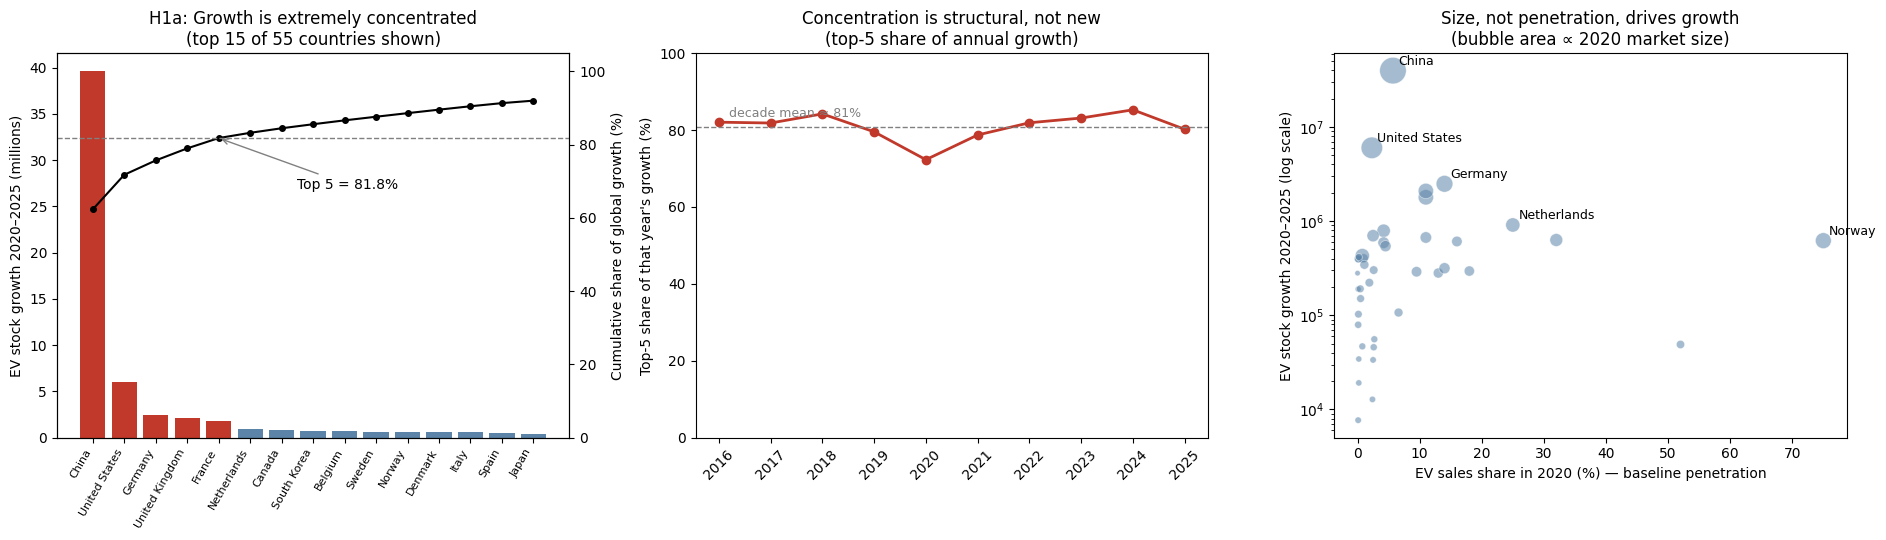

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# ── (1) Pareto: concentration of growth ──
ax = axes[0]
top = growth.sort_values(ascending=False)
cum = top.cumsum() / total * 100
n_show = 15
ax.bar(range(n_show), top.values[:n_show]/1e6,
       color=['#C0392B' if i < 5 else '#5B84A8' for i in range(n_show)])
ax2 = ax.twinx()
ax2.plot(range(n_show), cum.values[:n_show], 'k-o', ms=4, lw=1.5)
ax2.axhline(81.8, color='gray', ls='--', lw=1)
ax2.annotate('Top 5 = 81.8%', xy=(4, 81.8), xytext=(6.5, 68), fontsize=10,
             arrowprops=dict(arrowstyle='->', color='gray'))
ax2.set_ylim(0, 105); ax2.set_ylabel('Cumulative share of global growth (%)')
ax.set_xticks(range(n_show))
ax.set_xticklabels(top.index[:n_show], rotation=60, ha='right', fontsize=8)
ax.set_ylabel('EV stock growth 2020–2025 (millions)')
ax.set_title('H1a: Growth is extremely concentrated\n(top 15 of 55 countries shown)')

# ── (2) Concentration trend ──
ax = axes[1]
years, shares_t = [], []
for y in range(2016, 2026):
    gy = (stock[y] - stock[y-1]).dropna(); gy = gy[gy > 0]
    years.append(y); shares_t.append(gy.nlargest(5).sum()/gy.sum()*100)
ax.plot(years, shares_t, 'o-', color='#C0392B', lw=2)
ax.set_ylim(0, 100)
ax.axhline(np.mean(shares_t), color='gray', ls='--', lw=1)
ax.text(2016.2, np.mean(shares_t)+2.5, f'decade mean ≈ {np.mean(shares_t):.0f}%',
        fontsize=9, color='gray')
ax.set_ylabel("Top-5 share of that year's growth (%)")
ax.set_title('Concentration is structural, not new\n(top-5 share of annual growth)')
ax.set_xticks(years); ax.tick_params(axis='x', rotation=45)

# ── (3) Penetration vs growth, bubble = market size ──
ax = axes[2]
v = base_pen.notna() & growth.notna() & (growth > 0)
x, y = base_pen[v], growth[v]
sz = base_stock[v].fillna(base_stock[v].min()).clip(lower=1)
ax.scatter(x, y, s=np.sqrt(sz)/6 + 15, alpha=0.55, color='#5B84A8',
           edgecolor='white', lw=0.5)
ax.set_yscale('log')
for c in ['China', 'Norway', 'United States', 'Germany', 'Netherlands']:
    if c in x.index:
        ax.annotate(c, (x[c], y[c]), fontsize=9, xytext=(4, 4),
                    textcoords='offset points')
ax.set_xlabel('EV sales share in 2020 (%) — baseline penetration')
ax.set_ylabel('EV stock growth 2020–2025 (log scale)')
ax.set_title('Size, not penetration, drives growth\n(bubble area ∝ 2020 market size)')

plt.tight_layout()
plt.show()

1) The five largest markets captured 81.8% of global EV stock growth 2020–2025. (2) The top-5 share of annual growth has been stable near 80% for a decade. (3) Baseline penetration is a poor predictor of growth once market size is considered — large mid-penetration markets (China) dominate while saturated markets (Norway) contribute little.

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/OPIM 5606: Data Visualization/EV_master_analytical.xlsx'